# Промышленность

In [1]:
import sys
!{sys.executable} -m pip install sqlalchemy -q
%pip install -q phik


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: /home/adm-s/jupyter_env_py310/bin/python3.10 -m pip install --upgrade pip

[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: /home/adm-s/jupyter_env_py310/bin/python3.10 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from IPython.display import display
from sqlalchemy import create_engine
import phik
from phik.report import plot_correlation_matrix
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import KFold, cross_val_score, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error
from sklearn.dummy import DummyRegressor
import time
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
from scipy.stats import loguniform, randint, uniform
from sklearn.neural_network import MLPRegressor
import warnings, os
warnings.filterwarnings('ignore'); os.environ['PYTHONWARNINGS'] = 'ignore'
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import RobustScaler, QuantileTransformer
from sklearn.compose import TransformedTargetRegressor
from sklearn.metrics import r2_score
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import RidgeCV
from sklearn.ensemble import (ExtraTreesRegressor, HistGradientBoostingRegressor, StackingRegressor)
from sklearn.inspection import permutation_importance

## Предобработка данных

In [3]:
path_to_db = 'ds-plus-final.db'
engine = create_engine(f'sqlite:///{path_to_db}', echo=False) 

In [4]:
RANDOM_STATE = 190826

In [5]:
names = ['data_arc', 'data_bulk', 'data_bulk_time',
         'data_gas', 'data_temp', 'data_wire', 'data_wire_time']

dfs = {n: pd.read_sql(f'SELECT * FROM {n}', engine) for n in names}

data_arc = dfs['data_arc']
data_bulk = dfs['data_bulk']
data_bulk_time = dfs['data_bulk_time']
data_gas = dfs['data_gas']
data_temp = dfs['data_temp']
data_wire = dfs['data_wire']
data_wire_time = dfs['data_wire_time']

In [6]:
data_arc.head()

,key,Начало нагрева дугой,Конец нагрева дугой,Активная мощность,Реактивная мощность
0,1,2019-05-03 11:02:14,2019-05-03 11:06:02,0.305130,0.211253
1,1,2019-05-03 11:07:28,2019-05-03 11:10:33,0.765658,0.477438
2,1,2019-05-03 11:11:44,2019-05-03 11:14:36,0.580313,0.430460
3,1,2019-05-03 11:18:14,2019-05-03 11:24:19,0.518496,0.379979
4,1,2019-05-03 11:26:09,2019-05-03 11:28:37,0.867133,0.643691


In [7]:
data_bulk.head()

,key,Bulk 1,Bulk 2,Bulk 3,Bulk 4,Bulk 5,Bulk 6,Bulk 7,Bulk 8,Bulk 9,Bulk 10,Bulk 11,Bulk 12,Bulk 13,Bulk 14,Bulk 15
0,1,NaN,NaN,NaN,43.0,None,None,None,None,None,None,None,206.0,None,150.0,154.0
1,2,NaN,NaN,NaN,73.0,None,None,None,None,None,None,None,206.0,None,149.0,154.0
2,3,NaN,NaN,NaN,34.0,None,None,None,None,None,None,None,205.0,None,152.0,153.0
3,4,NaN,NaN,NaN,81.0,None,None,None,None,None,None,None,207.0,None,153.0,154.0
4,5,NaN,NaN,NaN,78.0,None,None,None,None,None,None,None,203.0,None,151.0,152.0


In [8]:
data_bulk_time.head()

,key,Bulk 1,Bulk 2,Bulk 3,Bulk 4,Bulk 5,Bulk 6,Bulk 7,Bulk 8,Bulk 9,Bulk 10,Bulk 11,Bulk 12,Bulk 13,Bulk 14,Bulk 15
0,1,None,None,None,2019-05-03 11:28:48,None,None,None,None,None,None,None,2019-05-03 11:24:31,None,2019-05-03 11:14:50,2019-05-03 11:10:43
1,2,None,None,None,2019-05-03 11:36:50,None,None,None,None,None,None,None,2019-05-03 11:53:30,None,2019-05-03 11:48:37,2019-05-03 11:44:39
2,3,None,None,None,2019-05-03 12:32:39,None,None,None,None,None,None,None,2019-05-03 12:27:13,None,2019-05-03 12:21:01,2019-05-03 12:16:16
3,4,None,None,None,2019-05-03 12:43:22,None,None,None,None,None,None,None,2019-05-03 12:58:00,None,2019-05-03 12:51:11,2019-05-03 12:46:36
4,5,None,None,None,2019-05-03 13:30:47,None,None,None,None,None,None,None,2019-05-03 13:30:47,None,2019-05-03 13:34:12,2019-05-03 13:30:47


In [9]:
data_gas.head()

,key,Газ 1
0,1,29.749986
1,2,12.555561
2,3,28.554793
3,4,18.841219
4,5,5.413692


In [10]:
data_temp.head()

,key,Время замера,Температура
0,1,2019-05-03 11:02:04,1571.0
1,1,2019-05-03 11:07:18,1604.0
2,1,2019-05-03 11:11:34,1618.0
3,1,2019-05-03 11:18:04,1601.0
4,1,2019-05-03 11:25:59,1606.0


In [11]:
data_wire.head()

,key,Wire 1,Wire 2,Wire 3,Wire 4,Wire 5,Wire 6,Wire 7,Wire 8,Wire 9
0,1,60.059998,None,None,None,None,None,None,None,None
1,2,96.052315,None,None,None,None,None,None,None,None
2,3,91.160157,None,None,None,None,None,None,None,None
3,4,89.063515,None,None,None,None,None,None,None,None
4,5,89.238236,9.11456,None,None,None,None,None,None,None


In [12]:
data_wire_time.head()

,key,Wire 1,Wire 2,Wire 3,Wire 4,Wire 5,Wire 6,Wire 7,Wire 8,Wire 9
0,1,2019-05-03 11:06:19,None,None,None,None,None,None,None,None
1,2,2019-05-03 11:36:50,None,None,None,None,None,None,None,None
2,3,2019-05-03 12:11:46,None,None,None,None,None,None,None,None
3,4,2019-05-03 12:43:22,None,None,None,None,None,None,None,None
4,5,2019-05-03 13:20:44,2019-05-03 13:15:34,None,None,None,None,None,None,None


In [13]:
def show_info(dfs, n_head=5, describe=True):
    for name, df in dfs.items():
        print(f'ТАБЛИЦА: {name}   |   строк: {df.shape[0]}   столбцов: {df.shape[1]}', end='')
        if 'key' in df.columns:
            print(f'   уникальных key: {df["key"].nunique()}')
        else:
            print()

        df.info()

        print(f'\nПолных дубликатов: {df.duplicated().sum()}')

        na = df.isna().sum()
        na = na[na > 0]
        if len(na):
            print('\nПропуски:')
            display(pd.DataFrame({'кол-во': na,
                                  'доля, %': (na / len(df) * 100).round(1)}))
        else:
            print('Пропусков нет')

        if describe:
            print('Описательная статистика:')
            display(df.describe(include='all').T)
        print()

In [14]:
show_info(dfs)

ТАБЛИЦА: data_arc   |   строк: 14876   столбцов: 5   уникальных key: 3214
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14876 entries, 0 to 14875
Data columns (total 5 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   key                   14876 non-null  int64  
 1   Начало нагрева дугой  14876 non-null  object 
 2   Конец нагрева дугой   14876 non-null  object 
 3   Активная мощность     14876 non-null  float64
 4   Реактивная мощность   14876 non-null  float64
dtypes: float64(2), int64(1), object(2)
memory usage: 581.2+ KB

Полных дубликатов: 0
Пропусков нет
Описательная статистика:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
key,14876.0,NaN,NaN,NaN,1615.220422,934.571502,1.0,806.0,1617.0,2429.0,3241.0
Начало нагрева дугой,14876,14876,2019-05-03 11:02:14,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Конец нагрева дугой,14876,14876,2019-05-03 11:06:02,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Активная мощность,14876.0,NaN,NaN,NaN,0.662752,0.258885,0.22312,0.467115,0.599587,0.83007,1.463773
Реактивная мощность,14876.0,NaN,NaN,NaN,0.438986,5.873485,-715.479924,0.337175,0.441639,0.608201,1.270284



ТАБЛИЦА: data_bulk   |   строк: 3129   столбцов: 16   уникальных key: 3129
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3129 entries, 0 to 3128
Data columns (total 16 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   key      3129 non-null   int64  
 1   Bulk 1   252 non-null    float64
 2   Bulk 2   22 non-null     float64
 3   Bulk 3   1298 non-null   float64
 4   Bulk 4   1014 non-null   float64
 5   Bulk 5   77 non-null     object 
 6   Bulk 6   576 non-null    object 
 7   Bulk 7   25 non-null     object 
 8   Bulk 8   1 non-null      object 
 9   Bulk 9   19 non-null     object 
 10  Bulk 10  176 non-null    object 
 11  Bulk 11  177 non-null    object 
 12  Bulk 12  2450 non-null   object 
 13  Bulk 13  18 non-null     object 
 14  Bulk 14  2806 non-null   object 
 15  Bulk 15  2248 non-null   object 
dtypes: float64(4), int64(1), object(11)
memory usage: 391.2+ KB

Полных дубликатов: 0

Пропуски:


,кол-во,"доля, %"
Bulk 1,2877,91.9
Bulk 2,3107,99.3
Bulk 3,1831,58.5
Bulk 4,2115,67.6
Bulk 5,3052,97.5
Bulk 6,2553,81.6
Bulk 7,3104,99.2
Bulk 8,3128,100.0
Bulk 9,3110,99.4
Bulk 10,2953,94.4


Описательная статистика:


...

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
key,3081.0,NaN,NaN,NaN,1623.426485,932.996726,1.0,823.0,1619.0,2434.0,3241.0
Wire 1,3055.0,NaN,NaN,NaN,100.895853,42.012518,1.9188,72.115684,100.158234,126.060483,330.314424
Wire 2,1079,713,30.09968,20,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Wire 3,63,56,93.165077,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Wire 4,14,14,24.148801,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Wire 5,1,1,15.132,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Wire 6,73,69,18.086641,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Wire 7,11,10,12.354473,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Wire 8,19,13,46.187439000000005,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Wire 9,29,25,30.066399,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN



ТАБЛИЦА: data_wire_time   |   строк: 3081   столбцов: 10   уникальных key: 3081
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3081 entries, 0 to 3080
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   key     3081 non-null   int64 
 1   Wire 1  3055 non-null   object
 2   Wire 2  1079 non-null   object
 3   Wire 3  63 non-null     object
 4   Wire 4  14 non-null     object
 5   Wire 5  1 non-null      object
 6   Wire 6  73 non-null     object
 7   Wire 7  11 non-null     object
 8   Wire 8  19 non-null     object
 9   Wire 9  29 non-null     object
dtypes: int64(1), object(9)
memory usage: 240.8+ KB

Полных дубликатов: 0

Пропуски:


,кол-во,"доля, %"
Wire 1,26,0.8
Wire 2,2002,65.0
Wire 3,3018,98.0
Wire 4,3067,99.5
Wire 5,3080,100.0
Wire 6,3008,97.6
Wire 7,3070,99.6
Wire 8,3062,99.4
Wire 9,3052,99.1


Описательная статистика:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
key,3081.0,NaN,NaN,NaN,1623.426485,932.996726,1.0,823.0,1619.0,2434.0,3241.0
Wire 1,3055,3055,2019-05-03 11:06:19,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Wire 2,1079,1079,2019-05-03 13:15:34,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Wire 3,63,63,2019-05-04 04:34:27,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Wire 4,14,14,2019-05-07 15:19:17,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Wire 5,1,1,2019-08-13 06:14:30,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Wire 6,73,73,2019-05-07 14:46:05,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Wire 7,11,11,2019-07-27 05:49:05,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Wire 8,19,19,2019-05-14 11:29:24,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Wire 9,29,29,2019-05-04 17:21:27,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Вывод
Все таблицы содержат данные, количесство таблиц соответствует условию задачи

## Исследовательский анализ

Строк с отрицательной реактивной мощностью: 1


,key,begin_heat,end_heat,active_power,reactive_power
9780,2116,2019-07-28 02:22:08,2019-07-28 02:23:57,0.705344,-715.479924


Все строки этой партии:


,key,begin_heat,end_heat,active_power,reactive_power
9778,2116,2019-07-28 02:07:12,2019-07-28 02:09:14,0.787549,0.693881
9779,2116,2019-07-28 02:13:10,2019-07-28 02:15:25,0.580263,0.411498
9780,2116,2019-07-28 02:22:08,2019-07-28 02:23:57,0.705344,-715.479924
9781,2116,2019-07-28 02:29:11,2019-07-28 02:30:18,0.563641,0.408513


count    14876.000000
mean       171.670946
std         98.186803
min         11.000000
25%        107.000000
50%        147.000000
75%        214.000000
max        907.000000
Name: heat_sec, dtype: float64
Нулевая/отрицательная длительность: 0
Нагревов дольше часа: 0


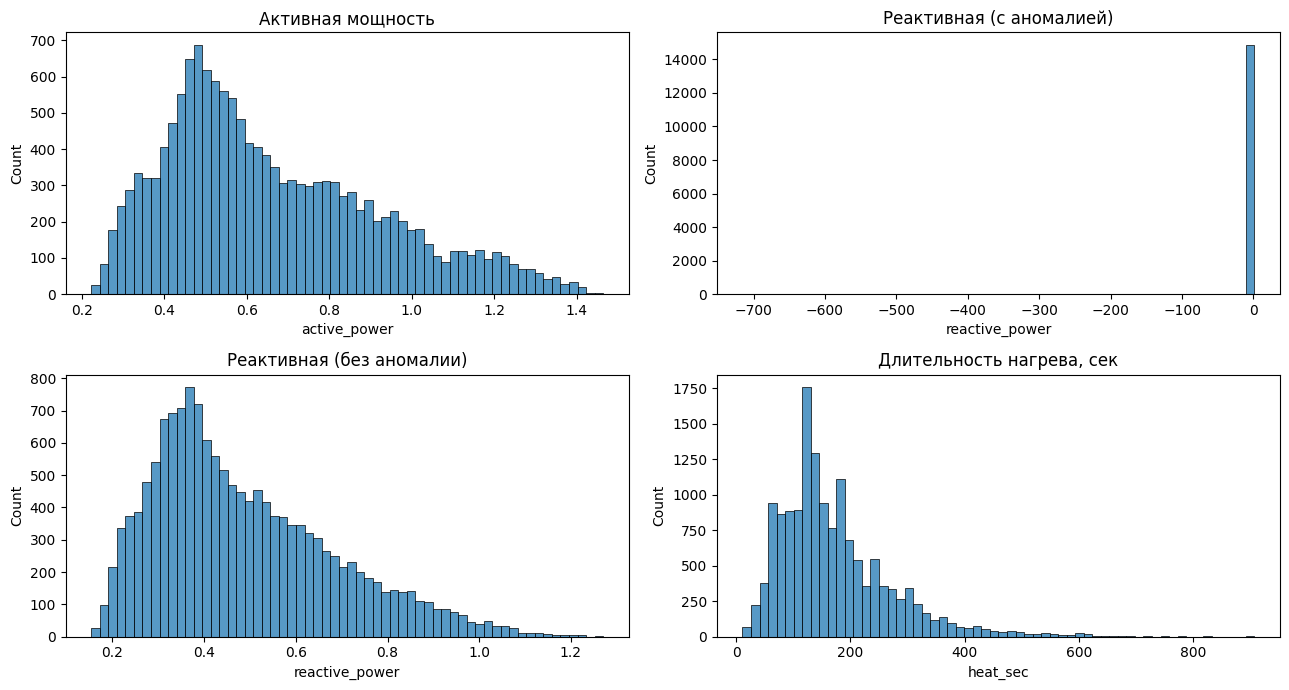

Нормальный диапазон по IQR: [-0.069, 1.015]
Медиана нормальных наблюдений: 0.442


count    3214.000000
mean        4.628500
std         1.608647
min         1.000000
25%         4.000000
50%         4.000000
75%         6.000000
max        16.000000
dtype: float64

In [15]:
arc = data_arc.copy()
arc.columns = ['key', 'begin_heat', 'end_heat', 'active_power', 'reactive_power']
arc['begin_heat'] = pd.to_datetime(arc['begin_heat'])
arc['end_heat']   = pd.to_datetime(arc['end_heat'])

print('Строк с отрицательной реактивной мощностью:', (arc['reactive_power'] < 0).sum())
display(arc[arc['reactive_power'] < 0])
print('Все строки этой партии:')
display(arc[arc['key'].isin(arc.loc[arc['reactive_power'] < 0, 'key'])])

arc['heat_sec'] = (arc['end_heat'] - arc['begin_heat']).dt.total_seconds()
print(arc['heat_sec'].describe())
print('Нулевая/отрицательная длительность:', (arc['heat_sec'] <= 0).sum())
print('Нагревов дольше часа:', (arc['heat_sec'] > 3600).sum())

fig, ax = plt.subplots(2, 2, figsize=(13, 7))
sns.histplot(arc['active_power'], bins=60, ax=ax[0,0]).set_title('Активная мощность')
sns.histplot(arc['reactive_power'], bins=60, ax=ax[0,1]).set_title('Реактивная (с аномалией)')
sns.histplot(arc.loc[arc['reactive_power'] > 0, 'reactive_power'],
             bins=60, ax=ax[1,0]).set_title('Реактивная (без аномалии)')
sns.histplot(arc['heat_sec'], bins=60, ax=ax[1,1]).set_title('Длительность нагрева, сек')
plt.tight_layout(); plt.show()

clean = arc.loc[arc['reactive_power'] > 0, 'reactive_power']
q1, q3 = clean.quantile([.25, .75]); iqr = q3 - q1

print(f'Нормальный диапазон по IQR: [{q1 - 1.5*iqr:.3f}, {q3 + 1.5*iqr:.3f}]')
print('Медиана нормальных наблюдений:', round(clean.median(), 3))

arc.groupby('key').size().describe()

В data_arc найдена одна строка с аномалией, заменб значение на медиану, чтобы не удалять 5 строк.

In [16]:
arc.loc[arc['reactive_power'] < 0, 'reactive_power'] = np.nan
arc['reactive_power'] = arc['reactive_power'].fillna(arc['reactive_power'].median())

In [17]:
arc.describe()

,key,begin_heat,end_heat,active_power,reactive_power,heat_sec
count,14876.000000,14876,14876,14876.000000,14876.000000,14876.000000
mean,1615.220422,2019-07-05 12:25:51.921081088,2019-07-05 12:28:43.592027392,0.662752,0.487112,171.670946
min,1.000000,2019-05-03 11:02:14,2019-05-03 11:06:02,0.223120,0.153777,11.000000
25%,806.000000,2019-06-03 23:18:23.249999872,2019-06-03 23:21:35,0.467115,0.337192,107.000000
50%,1617.000000,2019-07-03 01:31:26.500000,2019-07-03 01:35:13,0.599587,0.441665,147.000000
75%,2429.000000,2019-08-07 22:52:20.750000128,2019-08-07 22:56:47,0.830070,0.608201,214.000000
max,3241.000000,2019-09-06 17:24:54,2019-09-06 17:26:15,1.463773,1.270284,907.000000
std,934.571502,NaN,NaN,0.258885,0.197606,98.186803


In [18]:
data_arc.head()

,key,Начало нагрева дугой,Конец нагрева дугой,Активная мощность,Реактивная мощность
0,1,2019-05-03 11:02:14,2019-05-03 11:06:02,0.305130,0.211253
1,1,2019-05-03 11:07:28,2019-05-03 11:10:33,0.765658,0.477438
2,1,2019-05-03 11:11:44,2019-05-03 11:14:36,0.580313,0.430460
3,1,2019-05-03 11:18:14,2019-05-03 11:24:19,0.518496,0.379979
4,1,2019-05-03 11:26:09,2019-05-03 11:28:37,0.867133,0.643691


Добавила длительность нагрева дуги в секундах

In [19]:
arc['heat_sec']      = (arc['end_heat'] - arc['begin_heat']).dt.total_seconds()
arc['full_power']    = np.hypot(arc['active_power'], arc['reactive_power'])
arc['power_ratio']   = arc['active_power'] / arc['reactive_power']
arc['cos_phi']       = arc['active_power'] / arc['full_power']
arc['energy']        = arc['active_power'] * arc['heat_sec'] / 3600
arc['energy_full']   = arc['full_power']   * arc['heat_sec'] / 3600

arc = arc.sort_values(['key', 'begin_heat'])
arc['pause_sec'] = (arc.groupby('key')['begin_heat'].diff().dt.total_seconds()
                    - arc.groupby('key')['heat_sec'].shift())

Добавила признаки: full_power - полная мощность, то что расходует ресурсы сети, за что платит комбинат, поможет в задаче экономии электроэнергии, power_ratio - соотношение активной к реактивной мощности, показывает, какая доля потребляемой мощности используется продуктивно, cos_phi - меняется от 0 до 1: чем ближе к единице, тем эффективнее используется электроэнергия, energy - определяет прирост температуры, самая прямая свзяь с целевым признаком, pause_sec - позволит увидеть утечку тепла, чем длиннее паузы, тем больше потери, тем ниже финальная температура при той же затраченной энергии.

Агрегация по key

In [20]:
g = arc.groupby('key')
arc_agg = pd.DataFrame({
    'arc_n_heats'      : g.size(),
    'arc_time_total'   : g['heat_sec'].sum(),
    'arc_time_mean'    : g['heat_sec'].mean(),
    'arc_time_max'     : g['heat_sec'].max(),
    'arc_active_sum'   : g['active_power'].sum(),
    'arc_active_mean'  : g['active_power'].mean(),
    'arc_active_max'   : g['active_power'].max(),
    'arc_reactive_sum' : g['reactive_power'].sum(),
    'arc_reactive_mean': g['reactive_power'].mean(),
    'arc_full_sum'     : g['full_power'].sum(),
    'arc_full_mean'    : g['full_power'].mean(),
    'arc_ratio_mean'   : g['power_ratio'].mean(),
    'arc_cosphi_mean'  : g['cos_phi'].mean(),
    'arc_energy'       : g['energy'].sum(),
    'arc_energy_full'  : g['energy_full'].sum(),
    'arc_pause_mean'   : g['pause_sec'].mean(),
    'arc_pause_total'  : g['pause_sec'].sum(),
})

arc_agg['arc_span_sec'] = (g['end_heat'].max() - g['begin_heat'].min()).dt.total_seconds()
arc_agg['arc_duty'] = arc_agg['arc_time_total'] / arc_agg['arc_span_sec'].replace(0, np.nan)

arc_agg[['arc_pause_mean', 'arc_pause_total']] = arc_agg[['arc_pause_mean', 'arc_pause_total']].fillna(0)
arc_agg['arc_duty'] = arc_agg['arc_duty'].fillna(1)

In [21]:
arc_agg.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3214 entries, 1 to 3241
Data columns (total 19 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   arc_n_heats        3214 non-null   int64  
 1   arc_time_total     3214 non-null   float64
 2   arc_time_mean      3214 non-null   float64
 3   arc_time_max       3214 non-null   float64
 4   arc_active_sum     3214 non-null   float64
 5   arc_active_mean    3214 non-null   float64
 6   arc_active_max     3214 non-null   float64
 7   arc_reactive_sum   3214 non-null   float64
 8   arc_reactive_mean  3214 non-null   float64
 9   arc_full_sum       3214 non-null   float64
 10  arc_full_mean      3214 non-null   float64
 11  arc_ratio_mean     3214 non-null   float64
 12  arc_cosphi_mean    3214 non-null   float64
 13  arc_energy         3214 non-null   float64
 14  arc_energy_full    3214 non-null   float64
 15  arc_pause_mean     3214 non-null   float64
 16  arc_pause_total    3214 non-n

In [22]:
arc_agg.head()

,arc_n_heats,arc_time_total,arc_time_mean,arc_time_max,arc_active_sum,arc_active_mean,arc_active_max,arc_reactive_sum,arc_reactive_mean,arc_full_sum,arc_full_mean,arc_ratio_mean,arc_cosphi_mean,arc_energy,arc_energy_full,arc_pause_mean,arc_pause_total,arc_span_sec,arc_duty
key,,,,,,,,,,,,,,,,,,,
1,5,1098.0,219.60,365.0,3.036730,0.607346,0.867133,2.142821,0.428564,3.718736,0.743747,1.421570,0.816686,0.174616,0.213967,121.250000,485.0,1583.0,0.693620
2,4,811.0,202.75,338.0,2.139408,0.534852,0.786322,1.453357,0.363339,2.588349,0.647087,1.479201,0.825276,0.109800,0.133822,111.000000,333.0,1144.0,0.708916
3,5,655.0,131.00,280.0,4.063641,0.812728,1.222963,2.937457,0.587491,5.019223,1.003845,1.396069,0.809724,0.161604,0.200788,217.500000,870.0,1525.0,0.429508
4,4,741.0,185.25,278.0,2.706489,0.676622,0.887855,2.056992,0.514248,3.400038,0.850010,1.307446,0.793923,0.151031,0.189849,117.333333,352.0,1093.0,0.677951
5,4,869.0,217.25,415.0,2.252950,0.563238,0.892957,1.687991,0.421998,2.816980,0.704245,1.328894,0.796818,0.114495,0.142269,164.333333,493.0,1362.0,0.638032


In [23]:
arc_agg.describe()

,arc_n_heats,arc_time_total,arc_time_mean,arc_time_max,arc_active_sum,arc_active_mean,arc_active_max,arc_reactive_sum,arc_reactive_mean,arc_full_sum,arc_full_mean,arc_ratio_mean,arc_cosphi_mean,arc_energy,arc_energy_full,arc_pause_mean,arc_pause_total,arc_span_sec,arc_duty
count,3214.000000,3214.000000,3214.000000,3214.000000,3214.000000,3214.000000,3214.000000,3214.000000,3214.000000,3214.000000,3214.000000,3214.000000,3214.000000,3214.000000,3214.000000,3214.000000,3214.000000,3214.000000,3214.000000
mean,4.628500,794.579029,172.339290,288.464219,3.067549,0.661331,0.961701,2.254600,0.485967,3.811038,0.821565,1.373776,0.805932,0.146626,0.182110,309.233004,1130.649969,1925.228998,0.465875
std,1.608647,332.448622,45.606667,109.670010,1.208554,0.128372,0.231487,0.894663,0.097585,1.502643,0.160110,0.066162,0.013939,0.069097,0.085818,215.582565,1093.545181,1274.076219,0.165508
min,1.000000,57.000000,57.000000,57.000000,0.267676,0.267676,0.267676,0.196228,0.196228,0.331897,0.331897,1.099589,0.739789,0.007274,0.009286,0.000000,0.000000,57.000000,0.080882
25%,4.000000,571.000000,140.000000,208.000000,2.236770,0.573035,0.796996,1.631915,0.417415,2.776480,0.711251,1.331071,0.797305,0.099662,0.123507,171.375000,553.000000,1280.000000,0.340810
50%,4.000000,770.000000,168.750000,273.000000,2.984581,0.652974,0.966952,2.176833,0.481639,3.694219,0.812409,1.374350,0.806411,0.138572,0.172250,258.666667,881.000000,1691.000000,0.458459
75%,6.000000,983.000000,200.383333,342.000000,3.775472,0.739388,1.148873,2.788330,0.543312,4.696915,0.916602,1.418234,0.815580,0.185881,0.229909,382.875000,1452.750000,2326.000000,0.582909
max,16.000000,4189.000000,380.000000,907.000000,12.375636,1.243889,1.463773,8.949049,0.960763,15.288271,1.572238,1.663366,0.857042,1.032793,1.262891,3173.200000,19296.000000,23485.000000,1.000000


Агрегация прошла успешно, новых аномалий или пропусков не появилось

In [24]:
bulk = data_bulk.copy()
bulk.columns = ['key'] + [f'bulk_{i}' for i in range(1, 16)]

bulk_cols = [f'bulk_{i}' for i in range(1, 16)]
for c in bulk_cols:
    bulk[c] = pd.to_numeric(bulk[c], errors='coerce')

print(bulk.dtypes.value_counts())
display(bulk[bulk_cols].describe().T)

float64    15
int64       1
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
bulk_1,252.0,39.242063,18.277654,10.0,27.00,31.0,46.00,185.0
bulk_2,22.0,253.045455,21.180578,228.0,242.00,251.5,257.75,325.0
bulk_3,1298.0,113.879045,75.483494,6.0,58.00,97.5,152.00,454.0
bulk_4,1014.0,104.394477,48.184126,12.0,72.00,102.0,133.00,281.0
bulk_5,77.0,107.025974,81.790646,11.0,70.00,86.0,132.00,603.0
bulk_6,576.0,118.925347,72.057776,17.0,69.75,100.0,157.00,503.0
bulk_7,25.0,305.600000,191.022904,47.0,155.00,298.0,406.00,772.0
bulk_8,1.0,49.000000,NaN,49.0,49.00,49.0,49.00,49.0
bulk_9,19.0,76.315789,21.720581,63.0,66.00,68.0,70.50,147.0
bulk_10,176.0,83.284091,26.060347,24.0,64.00,86.5,102.00,159.0


In [25]:
before = data_bulk.iloc[:, 1:].notna().sum().sum()
after  = bulk[bulk_cols].notna().sum().sum()
print(f'Непустых до: {before}, после: {after}, потеряно: {before - after}')

Непустых до: 11159, после: 11159, потеряно: 0


,непустых,"доля, %",min,медиана,max
bulk_14,2806,89.7,16.0,151.0,636.0
bulk_12,2450,78.3,53.0,208.0,1849.0
bulk_15,2248,71.8,1.0,160.0,405.0
bulk_3,1298,41.5,6.0,97.5,454.0
bulk_4,1014,32.4,12.0,102.0,281.0
bulk_6,576,18.4,17.0,100.0,503.0
bulk_1,252,8.1,10.0,31.0,185.0
bulk_11,177,5.7,8.0,64.0,313.0
bulk_10,176,5.6,24.0,86.5,159.0
bulk_5,77,2.5,11.0,86.0,603.0


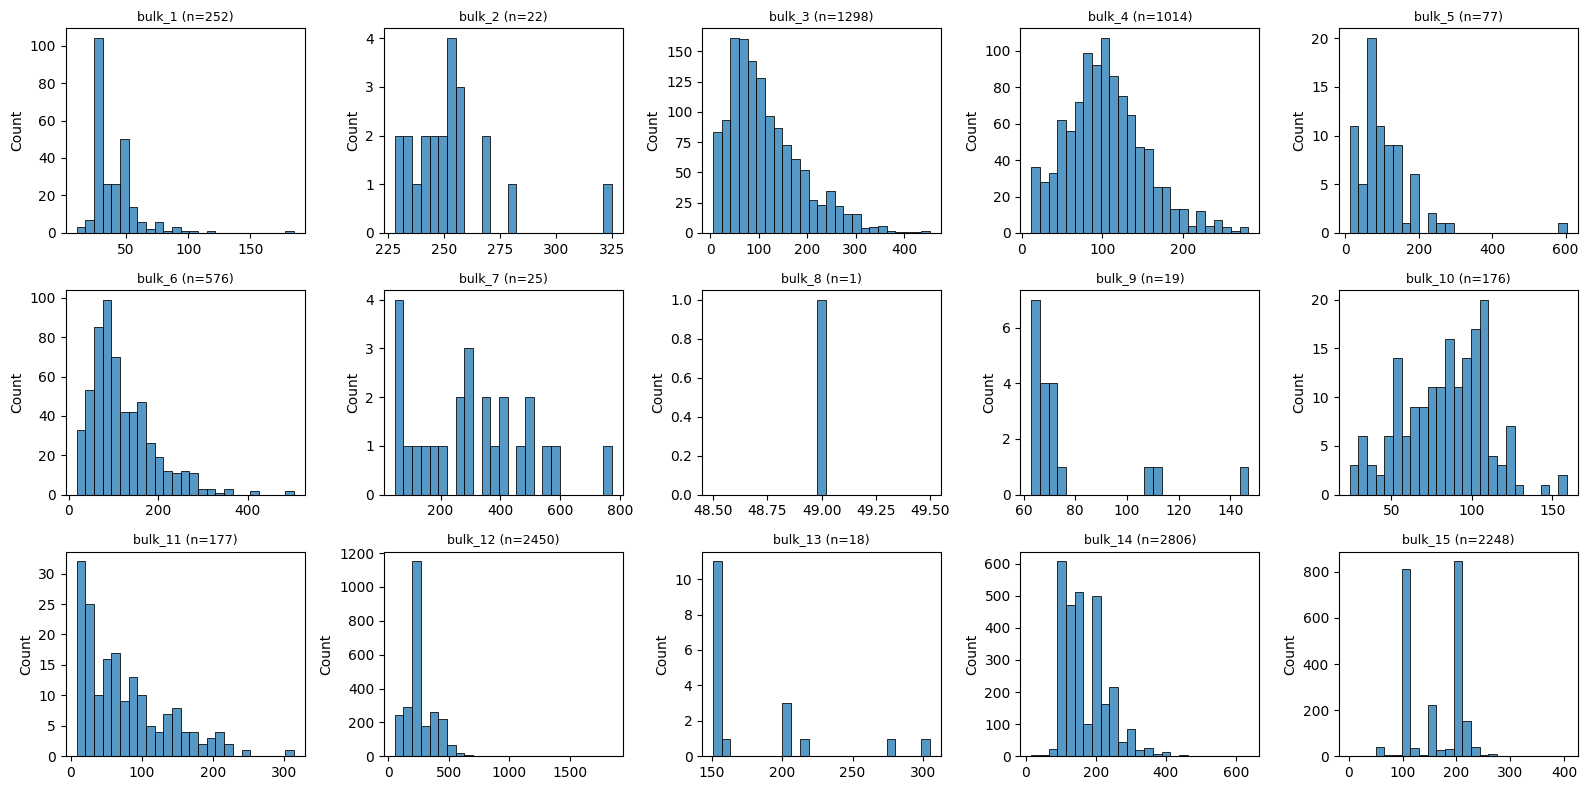

count    3129.000000
mean        3.566315
std         1.216165
min         1.000000
25%         3.000000
50%         4.000000
75%         4.000000
max         7.000000
dtype: float64
Партий вообще без сыпучих: 0


In [26]:
stat = pd.DataFrame({
    'непустых'   : bulk[bulk_cols].notna().sum(),
    'доля, %'    : (bulk[bulk_cols].notna().mean() * 100).round(1),
    'min'        : bulk[bulk_cols].min(),
    'медиана'    : bulk[bulk_cols].median(),
    'max'        : bulk[bulk_cols].max(),
}).sort_values('непустых', ascending=False)
display(stat)

fig, axes = plt.subplots(3, 5, figsize=(16, 8))
for ax, c in zip(axes.ravel(), bulk_cols):
    v = bulk[c].dropna()
    if len(v):
        sns.histplot(v, bins=25, ax=ax)
    ax.set_title(f'{c} (n={len(v)})', fontsize=9)
    ax.set_xlabel('')
plt.tight_layout(); plt.show()

# сколько разных материалов подают в одну партию
n_types = bulk[bulk_cols].notna().sum(axis=1)
print(n_types.describe())
print('Партий вообще без сыпучих:', (n_types == 0).sum())

In [27]:
bulk_filled = bulk.set_index('key')[bulk_cols].fillna(0)

#Редкие материалы отбрасываем (встречаются менее чем в 30 партиях)
keep = [c for c in bulk_cols if bulk[c].notna().sum() >= 30]
print('Оставляем:', keep)
print('Убираем:', sorted(set(bulk_cols) - set(keep)))

bulk_agg = bulk_filled[keep].copy()

# Агрегирующие признаки по всем материалам, включая редкие
bulk_agg['bulk_total']   = bulk_filled.sum(axis=1)# суммарная масса
bulk_agg['bulk_n_types'] = bulk.set_index('key')[bulk_cols].notna().sum(axis=1)

Оставляем: ['bulk_1', 'bulk_3', 'bulk_4', 'bulk_5', 'bulk_6', 'bulk_10', 'bulk_11', 'bulk_12', 'bulk_14', 'bulk_15']
Убираем: ['bulk_13', 'bulk_2', 'bulk_7', 'bulk_8', 'bulk_9']


В таблице 3129 партий, дубликатов нет, ключ уникален. 11 столбцов прочитались как object — приведены к числовому типу. Пропуски составляют от 10 % (bulk_14) до 100 % (bulk_8), но пропуск здесь означает, что материал не добавили, поэтому заполнен нулями. Шесть материалов встречаются менее чем в 2.5 % партий и исключены из признаков как неинформативные; их масса сохранена в агрегате bulk_total. 

Приведение типов и проверка согласованности data_bulk_time, так как пропуски совпадают с пропусками в data_bulk

In [28]:
bulk_time = data_bulk_time.copy()
bulk_time.columns = ['key'] + [f'bulk_{i}' for i in range(1, 16)]

bulk_cols = [f'bulk_{i}' for i in range(1, 16)]
for c in bulk_cols:
    bulk_time[c] = pd.to_datetime(bulk_time[c], errors='coerce')

print(bulk_time.dtypes.value_counts())

print('Ключи совпадают:', set(bulk['key']) == set(bulk_time['key']))

mask_vol  = bulk.set_index('key')[bulk_cols].isna()
mask_time = bulk_time.set_index('key')[bulk_cols].isna()
mismatch = (mask_vol != mask_time.loc[mask_vol.index]).sum().sum()
print('Расхождений между объёмом и временем:', mismatch)

datetime64[ns]    15
int64              1
Name: count, dtype: int64
Ключи совпадают: True
Расхождений между объёмом и временем: 0


Период данных: 2019-05-03 11:10:43 — 2019-09-06 17:26:33
Всего событий подачи: 11159
count    3129.000000
mean       16.081778
std        13.301467
min         0.000000
25%         8.083333
50%        14.616667
75%        21.850000
max       228.050000
dtype: float64

Партий с подачей дольше 1 часа : 27
Партий с подачей дольше 3 часов: 2
Партий с подачей дольше суток  : 0


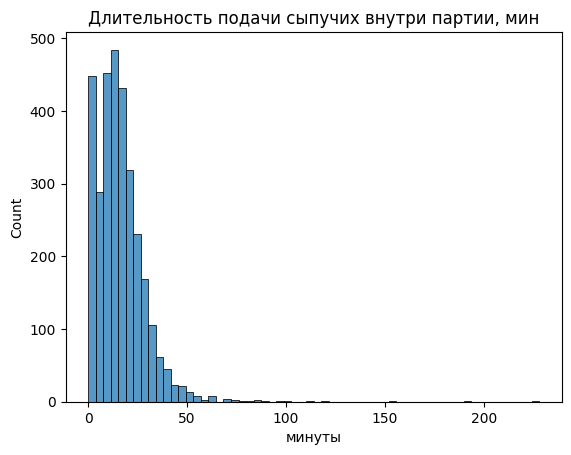


Интервал между подачами, мин:
count    8030.000000
mean        6.266486
std         6.617479
min         0.000000
25%         2.966667
50%         5.333333
75%         8.116667
max       211.183333
dtype: float64


In [29]:
all_times = bulk_time[bulk_cols].stack()
print('Период данных:', all_times.min(), '—', all_times.max())
print('Всего событий подачи:', len(all_times))

BT = bulk_time.set_index('key')[bulk_cols]
span_min = (BT.max(axis=1) - BT.min(axis=1)).dt.total_seconds() / 60

print(span_min.describe())
print('\nПартий с подачей дольше 1 часа :', (span_min > 60).sum())
print('Партий с подачей дольше 3 часов:', (span_min > 180).sum())
print('Партий с подачей дольше суток  :', (span_min > 1440).sum())

sns.histplot(span_min.dropna(), bins=60)
plt.title('Длительность подачи сыпучих внутри партии, мин')
plt.xlabel('минуты'); plt.show()

gaps = BT.apply(lambda r: r.dropna().sort_values().diff().dt.total_seconds().div(60), axis=1)
gaps_flat = gaps.stack() if isinstance(gaps, pd.DataFrame) else gaps.explode().dropna()
print('\nИнтервал между подачами, мин:')
print(pd.Series(gaps_flat.values, dtype=float).describe())

In [30]:
bulk_agg['bulk_span_min'] = span_min.fillna(0)         
bulk_agg['bulk_first_time'] = BT.min(axis=1)            
bulk_agg['bulk_last_time']  = BT.max(axis=1)

In [31]:
bulk_agg.describe()

,bulk_1,bulk_3,bulk_4,bulk_5,bulk_6,bulk_10,bulk_11,bulk_12,bulk_14,bulk_15,bulk_total,bulk_n_types,bulk_span_min,bulk_first_time,bulk_last_time
count,3129.000000,3129.000000,3129.000000,3129.000000,3129.000000,3129.000000,3129.000000,3129.000000,3129.000000,3129.000000,3129.000000,3129.000000,3129.000000,3129,3129
mean,3.160435,47.240332,33.830617,2.633749,21.892298,4.684564,4.345478,203.948226,152.706616,115.319271,595.503356,3.566315,16.081778,2019-07-05 20:31:19.313518336,2019-07-05 20:47:24.220198144
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,19.000000,1.000000,0.000000,2019-05-03 11:10:43,2019-05-03 11:28:48
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,105.000000,104.000000,0.000000,429.000000,3.000000,8.083333,2019-06-04 09:12:47,2019-06-04 09:22:40
50%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,206.000000,148.000000,106.000000,591.000000,4.000000,14.616667,2019-07-03 04:58:44,2019-07-03 05:17:25
75%,0.000000,80.000000,68.000000,0.000000,0.000000,0.000000,0.000000,263.000000,202.000000,204.000000,772.000000,4.000000,21.850000,2019-08-08 00:03:27,2019-08-08 00:23:14
max,185.000000,454.000000,281.000000,603.000000,503.000000,159.000000,313.000000,1849.000000,636.000000,405.000000,3235.000000,7.000000,228.050000,2019-09-06 17:23:15,2019-09-06 17:26:33
std,11.869164,74.239954,56.034505,20.918138,55.492582,20.157323,22.699580,151.419639,81.091421,84.488698,276.557794,1.216165,13.301467,NaN,NaN


Уникальных key: 3239 из 3239
Пропусков: 0
Нулевых или отрицательных: 0


count    3239.000000
mean       11.002062
std         6.220327
min         0.008399
25%         7.043089
50%         9.836267
75%        13.769915
max        77.995040
Name: gas, dtype: float64


Квантили хвостов:
0.001     0.287
0.010     1.133
0.050     3.197
0.950    22.626
0.990    31.559
0.999    51.190
Name: gas, dtype: float64


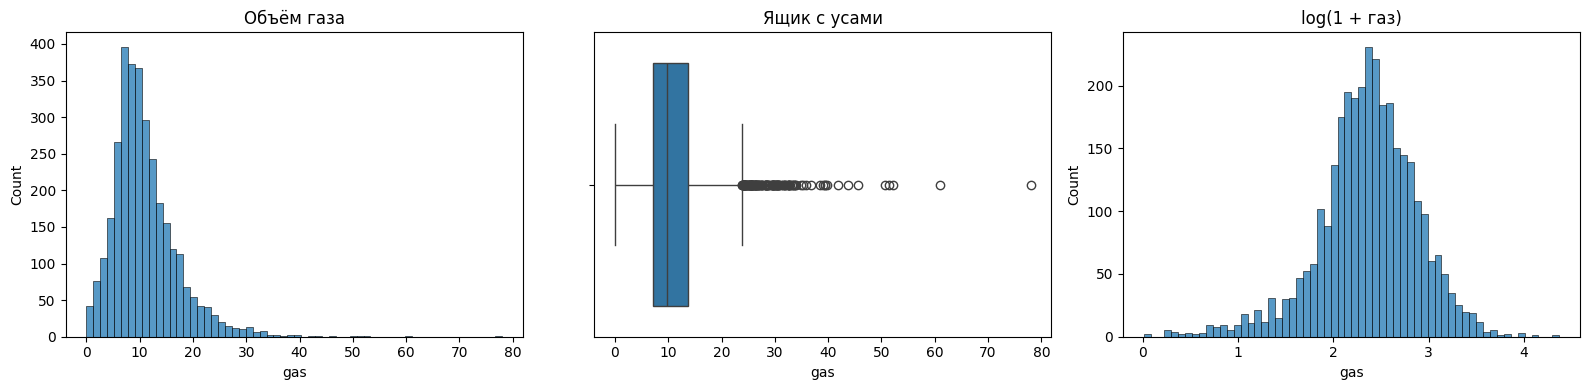


Границы по IQR: [-3.05, 23.86]
За верхней границей: 126 (3.9%)

Меньше 1: 23


,key,gas
863,866,0.008399
1044,1047,0.016696
2100,2103,0.263029
2353,2356,0.275081
352,355,0.325733
2466,2469,0.335164
2680,2683,0.338997
951,954,0.364256
1130,1133,0.364789
193,195,0.374436


,key,gas
319,322,77.995040
277,280,60.935689
2107,2110,52.142373
2567,2570,51.380229
116,117,50.581035
2105,2108,45.638999
1461,1464,43.655411
660,663,41.854643
525,528,39.728826
610,613,39.425706


In [32]:
gas = data_gas.copy()
gas.columns = ['key', 'gas']

print('Уникальных key:', gas['key'].nunique(), 'из', len(gas))
print('Пропусков:', gas['gas'].isna().sum())
print('Нулевых или отрицательных:', (gas['gas'] <= 0).sum())

display(gas['gas'].describe())
print('\nКвантили хвостов:')
print(gas['gas'].quantile([.001, .01, .05, .95, .99, .999]).round(3))

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(gas['gas'], bins=60, ax=ax[0]).set_title('Объём газа')
sns.boxplot(x=gas['gas'], ax=ax[1]).set_title('Ящик с усами')
sns.histplot(np.log1p(gas['gas']), bins=60, ax=ax[2]).set_title('log(1 + газ)')
plt.tight_layout(); plt.show()

q1, q3 = gas['gas'].quantile([.25, .75]); iqr = q3 - q1
lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
print(f'\nГраницы по IQR: [{lo:.2f}, {hi:.2f}]')
print('За верхней границей:', (gas['gas'] > hi).sum(),
      f'({(gas["gas"] > hi).mean():.1%})')

print('\nМеньше 1:', (gas['gas'] < 1).sum())
display(gas.nsmallest(10, 'gas'))
display(gas.nlargest(10, 'gas'))

Выбросы удалять не буду так как считаю, что это реальные длинные продувки на проблемных плавках

Добавлю признак

In [33]:
gas_agg = gas.set_index('key')

Приведение типов

In [34]:
temp = data_temp.copy()
temp.columns = ['key', 'measure_time', 'temperature']
temp['measure_time'] = pd.to_datetime(temp['measure_time'])
temp['temperature']  = pd.to_numeric(temp['temperature'], errors='coerce')

display(temp['temperature'].describe())

count    14665.000000
mean      1590.722741
std         20.394381
min       1191.000000
25%       1580.000000
50%       1590.000000
75%       1599.000000
max       1705.000000
Name: temperature, dtype: float64

In [35]:
print('Было пропусков:', data_temp.iloc[:, 2].isna().sum())
print('Стало пропусков:', temp['temperature'].isna().sum())

Было пропусков: 3427
Стало пропусков: 3427


Анализ пропусков

In [36]:
temp['is_na'] = temp['temperature'].isna()
by_month = temp.groupby(temp['measure_time'].dt.to_period('M'))['is_na'].agg(['sum', 'mean'])
display(by_month.round(3))

temp['pos'] = temp.groupby('key').cumcount() + 1
print(temp.groupby('pos')['is_na'].mean().head(10).round(3))

,sum,mean
measure_time,,
2019-05,0,0.000
2019-06,0,0.000
2019-07,0,0.000
2019-08,2691,0.574
2019-09,736,0.816


pos
1     0.000
2     0.230
3     0.231
4     0.231
5     0.229
6     0.230
7     0.224
8     0.247
9     0.230
10    0.255
Name: is_na, dtype: float64


Аномалии

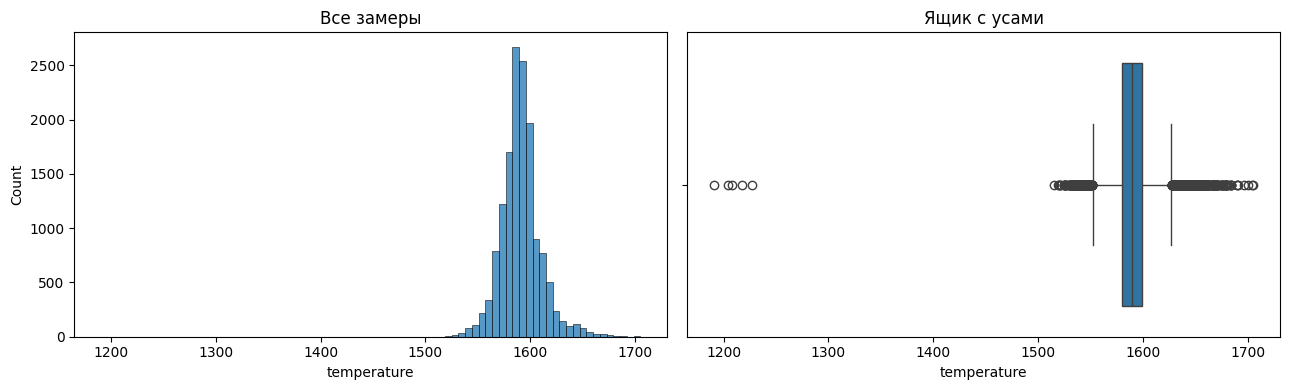

Замеров ниже 1500 °C: 5


,key,measure_time,temperature,is_na,pos
4883,867,2019-06-06 08:03:39,1191.0,False,1
6784,1214,2019-06-18 08:01:03,1208.0,False,1
9050,1619,2019-07-03 02:34:41,1218.0,False,1
11495,2052,2019-07-25 08:49:15,1227.0,False,1
14283,2561,2019-08-12 18:49:29,1204.0,False,1



Партии с аномалией: [ 867 1214 1619 2052 2561]


In [37]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(temp['temperature'].dropna(), bins=80, ax=ax[0]).set_title('Все замеры')
sns.boxplot(x=temp['temperature'].dropna(), ax=ax[1]).set_title('Ящик с усами')
plt.tight_layout(); plt.show()

print('Замеров ниже 1500 °C:', (temp['temperature'] < 1500).sum())
display(temp[temp['temperature'] < 1500])
print('\nПартии с аномалией:', temp.loc[temp['temperature'] < 1500, 'key'].unique())

Формирование целевого признака

In [40]:
t = temp.dropna(subset=['temperature']).copy()
t = t.sort_values(['key', 'measure_time'])

anomaly_mask = t['temperature'] < 1500
print(f'Аномальных замеров: {anomaly_mask.sum()}')
print(f'Затронуто партий:   {t.loc[anomaly_mask, "key"].nunique()}')
print(f'Ключи:              {t.loc[anomaly_mask, "key"].unique()}')

rank = t.groupby('key').cumcount()  
anomaly_not_first = anomaly_mask & (rank != 0)
assert anomaly_not_first.sum() == 0 

t_clean = t[~anomaly_mask].copy()

cnt = t_clean.groupby('key')['temperature'].size()
keys_ok = cnt[cnt >= 2].index
print(f'\nПартий с ≥2 валидными замерами: {len(keys_ok)} из {temp["key"].nunique()}')
t_clean = t_clean[t_clean['key'].isin(keys_ok)]

gt = t_clean.groupby('key')
temp_agg = pd.DataFrame({
    'temp_first': gt['temperature'].first(),
    'target':     gt['temperature'].last(),
    'n_measure':  gt['temperature'].size(),
})

time_marks = pd.DataFrame({
    'first_time': gt['measure_time'].first(),
    'last_time':  gt['measure_time'].last(),
})

Аномальных замеров: 5
Затронуто партий:   5
Ключи:              [ 867 1214 1619 2052 2561]

Партий с ≥2 валидными замерами: 2475 из 3216


Распределения

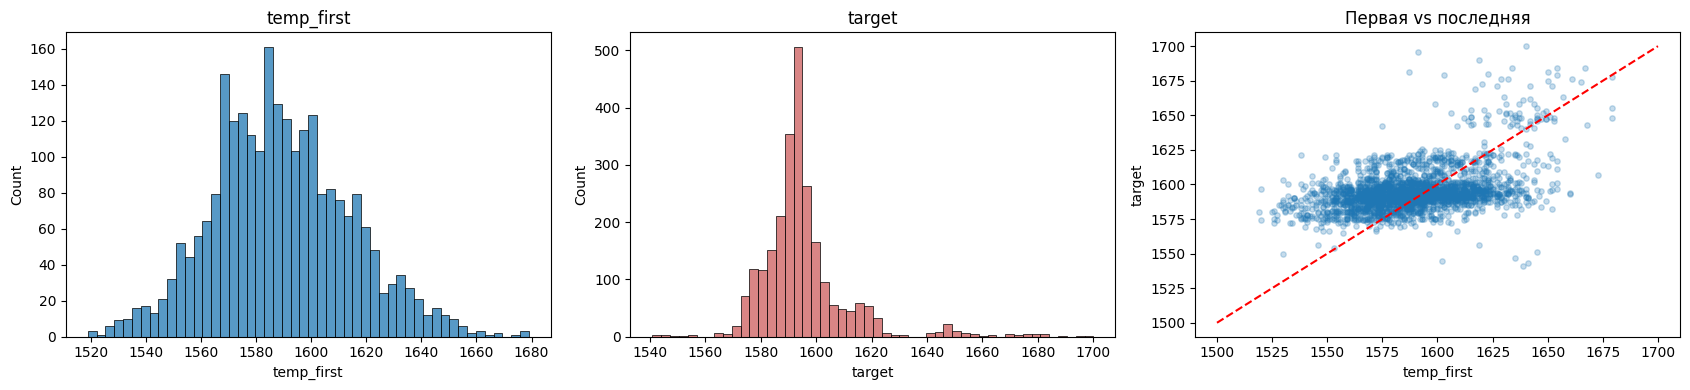

,temp_first,target,n_measure
count,2475.00,2475.00,2475.00
mean,1589.03,1595.34,5.62
std,25.00,16.02,1.61
min,1519.00,1541.00,2.00
25%,1572.00,1587.00,5.00
50%,1588.00,1593.00,5.00
75%,1605.00,1599.00,7.00
max,1679.00,1700.00,17.00


std temp_first: 25.0
std target    : 16.02
корреляция    : 0.437

Замеров на партию:
n_measure
2      33
3     136
4     394
5     689
6     579
7     389
8     151
9      66
10     21
11      7
12      3
13      2
14      2
16      2
17      1
Name: count, dtype: int64


In [41]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
sns.histplot(temp_agg['temp_first'], bins=50, ax=ax[0]).set_title('temp_first')
sns.histplot(temp_agg['target'], bins=50, ax=ax[1], color='indianred').set_title('target')
ax[2].scatter(temp_agg['temp_first'], temp_agg['target'], alpha=.25, s=15)
ax[2].plot([1500, 1700], [1500, 1700], 'r--')
ax[2].set_xlabel('temp_first'); ax[2].set_ylabel('target'); ax[2].set_title('Первая vs последняя')
plt.tight_layout(); plt.show()

display(temp_agg.describe().round(2))
print('std temp_first:', round(temp_agg['temp_first'].std(), 2))
print('std target    :', round(temp_agg['target'].std(), 2))
print('корреляция    :', round(temp_agg['temp_first'].corr(temp_agg['target']), 3))
print('\nЗамеров на партию:'); print(temp_agg['n_measure'].value_counts().sort_index())

Распределение целевого признака бимодально: основной пик - 1593 °C и второй, меньший, в районе 1640–1660 °C (5 % партий) — возможно отдельная марка стали с другой целевой температурой. Разброс целевого признака (std = 16.0) существенно ниже разброса начальной температуры (std = 25.0), корреляция между ними 0.437 —возможно операторы компенсируют низкую стартовую температуру более интенсивным нагревом. Все 5 аномальных замеров (1191–1227 °C) приходятся на первую позицию в партии, то есть в целевой признак не попадают; после их удаления роль начальной температуры переходит ко второму замеру, партии сохраняются.

Непустых до: 4344, после: 4344, потеряно: 0


,непустых,"доля, %",min,медиана,max
wire_1,3055,99.2,1.92,100.16,330.31
wire_2,1079,35.0,0.03,40.14,282.78
wire_6,73,2.4,0.03,42.08,180.45
wire_3,63,2.0,0.14,235.19,385.01
wire_9,29,0.9,4.62,30.07,90.05
wire_8,19,0.6,45.08,46.28,102.76
wire_4,14,0.5,24.15,45.23,113.23
wire_7,11,0.4,0.23,9.02,32.85
wire_5,1,0.0,15.13,15.13,15.13


Отрицательных или нулевых значений: 0


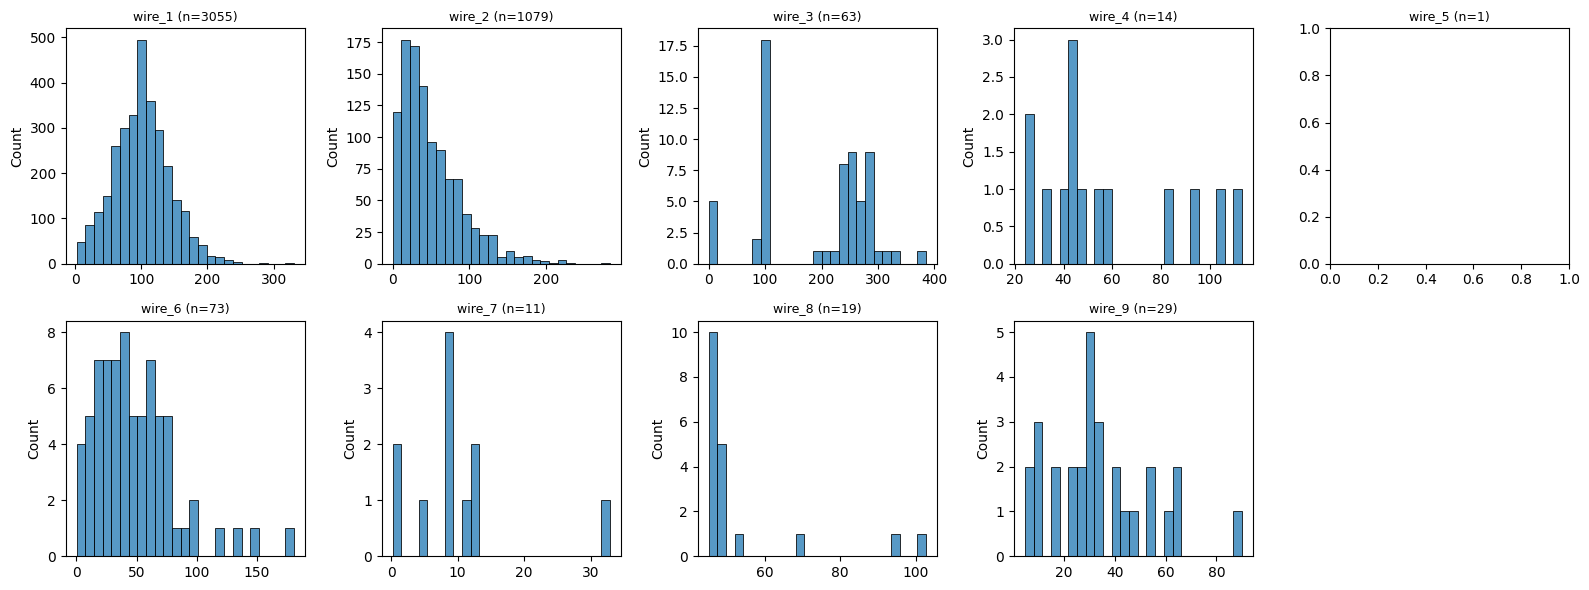

Видов проволоки на партию:
1    1936
2    1045
3      88
4       6
5       6
Name: count, dtype: int64
Партий вообще без проволоки: 0


In [42]:
wire = data_wire.copy()
wire.columns = ['key'] + [f'wire_{i}' for i in range(1, 10)]

wire_cols = [f'wire_{i}' for i in range(1, 10)]
for c in wire_cols:
    wire[c] = pd.to_numeric(wire[c], errors='coerce')

before = data_wire.iloc[:, 1:].notna().sum().sum()
after  = wire[wire_cols].notna().sum().sum()
print(f'Непустых до: {before}, после: {after}, потеряно: {before - after}')

stat = pd.DataFrame({
    'непустых': wire[wire_cols].notna().sum(),
    'доля, %' : (wire[wire_cols].notna().mean() * 100).round(1),
    'min'     : wire[wire_cols].min().round(2),
    'медиана' : wire[wire_cols].median().round(2),
    'max'     : wire[wire_cols].max().round(2),
}).sort_values('непустых', ascending=False)
display(stat)

print('Отрицательных или нулевых значений:', (wire[wire_cols] <= 0).sum().sum())

fig, axes = plt.subplots(2, 5, figsize=(16, 6))
for ax, c in zip(axes.ravel(), wire_cols):
    v = wire[c].dropna()
    if len(v) > 1:
        sns.histplot(v, bins=25, ax=ax)
    ax.set_title(f'{c} (n={len(v)})', fontsize=9)
    ax.set_xlabel('')
axes.ravel()[-1].axis('off')
plt.tight_layout(); plt.show()

n_types = wire[wire_cols].notna().sum(axis=1)
print('Видов проволоки на партию:'); print(n_types.value_counts().sort_index())
print('Партий вообще без проволоки:', (n_types == 0).sum())

Обработка пропусков

In [43]:
wire_filled = wire.set_index('key')[wire_cols].fillna(0)

keep_w = [c for c in wire_cols if wire[c].notna().sum() >= 30]
print('Оставляем:', keep_w)
print('Убираем:  ', sorted(set(wire_cols) - set(keep_w), key=lambda x: int(x.split('_')[1])))

wire_agg = wire_filled[keep_w].copy()

wire_agg['wire_total']   = wire_filled.sum(axis=1)
wire_agg['wire_n_types'] = wire.set_index('key')[wire_cols].notna().sum(axis=1)

print(wire_agg.shape)
display(wire_agg.describe().round(2))

Оставляем: ['wire_1', 'wire_2', 'wire_3', 'wire_6']
Убираем:   ['wire_4', 'wire_5', 'wire_7', 'wire_8', 'wire_9']
(3081, 6)


,wire_1,wire_2,wire_3,wire_6,wire_total,wire_n_types
count,3081.00,3081.00,3081.00,3081.00,3081.00,3081.00
mean,100.04,17.71,3.87,1.14,123.72,1.41
std,42.84,33.52,30.31,8.96,66.08,0.58
min,0.00,0.00,0.00,0.00,1.92,1.00
25%,70.28,0.00,0.00,0.00,86.11,1.00
50%,100.11,0.00,0.00,0.00,114.18,1.00
75%,125.80,23.16,0.00,0.00,150.18,2.00
max,330.31,282.78,385.01,180.45,663.85,5.00


Таблица содержит 3081 партию, ключ уникален, дубликатов нет. Восемь из девяти столбцов прочитались как object и приведены к числовому типу без потерь. В отличие от сыпучих материалов, объёмы проволоки непрерывны.
Пропуски составляют от 0.8% (wire_1) до 100% (wire_5) согласно пояснению заказчика пропуск означает, что материал не подавали, поэтому заполнен нулями. wire_1 — базовый материал, присутствует в 99.2 % партий; 26 партий без него сохранены с нулевым значением. Пять материалов (wire_4, 5, 7, 8, 9) встречаются менее чем в 30 партиях и исключены как неинформативные, их масса учтена в агрегате wire_total. Дополнительно сформирован признак wire_n_types — количество видов проволоки в партии.

Ключи совпадают: True
Расхождений объём/время: 0

Период данных: 2019-05-03 11:06:19 — 2019-09-06 17:10:06
Всего событий подачи: 4344

Видов проволоки на партию:
1    1936
2    1045
3      88
4       6
5       6
Name: count, dtype: int64

Длительность подачи, мин:
count    3081.00
mean        3.58
std         6.60
min         0.00
25%         0.00
50%         0.00
75%         6.68
max        98.95
dtype: float64
Дольше часа : 3
Дольше суток: 0


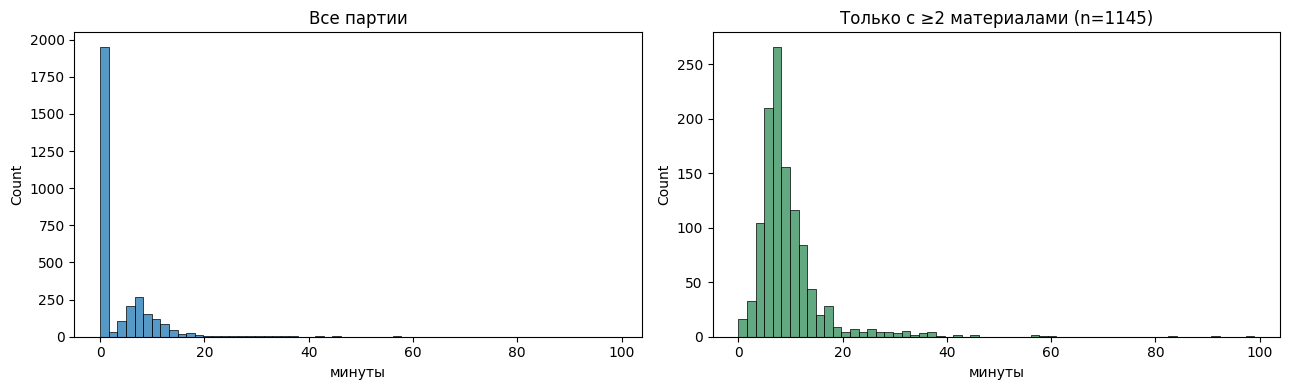


По партиям с ≥2 материалами:
count    1145.00
mean        9.62
std         7.69
min         0.00
25%         6.03
50%         7.83
75%        10.73
max        98.95
dtype: float64


In [44]:
wire_time = data_wire_time.copy()
wire_time.columns = ['key'] + [f'wire_{i}' for i in range(1, 10)]

wire_cols = [f'wire_{i}' for i in range(1, 10)]
for c in wire_cols:
    wire_time[c] = pd.to_datetime(wire_time[c], errors='coerce')

print('Ключи совпадают:', set(wire['key']) == set(wire_time['key']))
mask_vol  = wire.set_index('key')[wire_cols].isna()
mask_time = wire_time.set_index('key')[wire_cols].isna()
print('Расхождений объём/время:', (mask_vol != mask_time.loc[mask_vol.index]).sum().sum())

WT = wire_time.set_index('key')[wire_cols]
all_times = WT.stack()
print('\nПериод данных:', all_times.min(), '—', all_times.max())
print('Всего событий подачи:', len(all_times))

n_types_w = WT.notna().sum(axis=1)
print('\nВидов проволоки на партию:')
print(n_types_w.value_counts().sort_index())

span_w = (WT.max(axis=1) - WT.min(axis=1)).dt.total_seconds() / 60
print('\nДлительность подачи, мин:')
print(span_w.describe().round(2))
print('Дольше часа :', (span_w > 60).sum())
print('Дольше суток:', (span_w > 1440).sum())

multi = span_w[n_types_w >= 2]
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(span_w.dropna(), bins=60, ax=ax[0]).set_title('Все партии')
sns.histplot(multi, bins=60, ax=ax[1], color='seagreen').set_title(f'Только с ≥2 материалами (n={len(multi)})')
for a in ax: a.set_xlabel('минуты')
plt.tight_layout(); plt.show()

print('\nПо партиям с ≥2 материалами:')
print(multi.describe().round(2))

Cогласованность с нагревом

In [45]:
arc_span = arc.groupby('key').agg(arc_start=('begin_heat', 'min'), arc_end=('end_heat', 'max'))
chk = WT.min(axis=1).rename('wire_first').to_frame().join(WT.max(axis=1).rename('wire_last')).join(arc_span)
chk = chk.dropna()

print('Подача началась до первого нагрева:', (chk['wire_first'] < chk['arc_start']).sum())
print('Подача закончилась после последнего нагрева:', (chk['wire_last'] > chk['arc_end']).sum())

off = (chk['wire_first'] - chk['arc_start']).dt.total_seconds() / 60
print('\nСдвиг первой подачи от начала нагрева, мин:')
print(off.describe().round(1))

Подача началась до первого нагрева: 0
Подача закончилась после последнего нагрева: 145

Сдвиг первой подачи от начала нагрева, мин:
count    3080.0
mean        7.4
std        12.1
min         0.9
25%         2.4
50%         3.0
75%         9.5
max       360.1
dtype: float64


Признаки

In [46]:
wire_agg['wire_span_min'] = span_w.reindex(wire_agg.index).fillna(0)

wire_marks = pd.DataFrame({
    'wire_first_time': WT.min(axis=1),
    'wire_last_time' : WT.max(axis=1),
})

print(wire_agg.columns.tolist())

['wire_1', 'wire_2', 'wire_3', 'wire_6', 'wire_total', 'wire_n_types', 'wire_span_min']


Таблица содержит 3081 партию, ключ уникален, дубликатов нет, все столбцы приведены к datetime. Пропуски поячеечно идентичен data_wire — данные внутренне согласованы.

Зарегистрировано 4344 события подачи в период 03.05.2019–06.09.2019, совпадающий с остальными таблицами; некорректных дат нет. В 63 % партий подаётся один вид проволоки, в 34 % — два, максимум пять. Длительность подачи внутри партии: медиана 0 мин по всей выборке (следствие подачи единственного материала) и 7.8 мин по партиям с двумя и более материалами, максимум 99 минут при трёх случаях длительнее часа. Подача измеряется минутами, а не сутками.

Проверка согласованности с работой электродов показала, что подача проволоки никогда не начинается раньше первого нагрева. В 145 партиях подача завершается после последнего нагрева.

Из таблицы сформирован признак wire_span_min — длительность подачи проволоки внутри партии.

## Объединение

Так как заказчик написал, что "во все партии точно добавлялись сыпучие и проволочные материалы, везде была выполнена продувка газом и сплав всегда нагревался", то объединять буду через innner join, потому что партия без данных о нагреве или без продувки неполна, прогнозировать по ней нечего.

In [47]:
print('Ключей в таблицах:')
for name, df in [('temp', temp_agg), ('arc', arc_agg), ('gas', gas_agg),
                 ('bulk', bulk_agg), ('wire', wire_agg)]:
    print(f'  {name:5s}: {len(df)}')

common = (set(temp_agg.index) & set(arc_agg.index) & set(gas_agg.index)
          & set(bulk_agg.index) & set(wire_agg.index))
print('\nПартий с полным набором:', len(common))

data = (temp_agg
        .join(arc_agg,  how='inner')
        .join(gas_agg,  how='inner')
        .join(bulk_agg, how='inner')
        .join(wire_agg, how='inner'))

print('Итоговая таблица:', data.shape)
print('Уникальных ключей:', data.index.nunique(), '| строк:', len(data))
print('Дубликатов индекса:', data.index.duplicated().sum())
print('Пропусков всего:', data.isna().sum().sum())

Ключей в таблицах:
  temp : 2475
  arc  : 3214
  gas  : 3239
  bulk : 3129
  wire : 3081

Партий с полным набором: 2329
Итоговая таблица: (2329, 45)
Уникальных ключей: 2329 | строк: 2329
Дубликатов индекса: 0
Пропусков всего: 0


<div class="alert alert-success" style="border-color: green; border-radius: 5px">
    <p><u><b>✅ КОММЕНТАРИЙ МЕНТОРА</b></u></p>иннер поддерживаю) принято.

Асинхронность

In [48]:
bulk_marks = pd.DataFrame({
    'bulk_first_time': BT.min(axis=1),
    'bulk_last_time' : BT.max(axis=1),
})

wire_marks = pd.DataFrame({
    'wire_first_time': WT.min(axis=1),
    'wire_last_time' : WT.max(axis=1),
})

print(bulk_marks.shape, wire_marks.shape)
print(bulk_marks.dtypes)
data['bulk_first_delay'] = ((bulk_marks['bulk_first_time'] - time_marks['first_time'])
                            .dt.total_seconds() / 60).reindex(data.index)
data['wire_first_delay'] = ((wire_marks['wire_first_time'] - time_marks['first_time'])
                            .dt.total_seconds() / 60).reindex(data.index)

print('bulk_first_delay:'); print(data['bulk_first_delay'].describe().round(1))
print('\nОтрицательных (материал раньше первого замера):',
      (data['bulk_first_delay'] < 0).sum(), f"({(data['bulk_first_delay'] < 0).mean():.1%})")
print('wire отрицательных:', (data['wire_first_delay'] < 0).sum())

for c in ['bulk_first_delay', 'wire_first_delay']:
    data[c] = data[c].fillna(data[c].median())

(3129, 2) (3081, 2)
bulk_first_time    datetime64[ns]
bulk_last_time     datetime64[ns]
dtype: object
bulk_first_delay:
count    2329.0
mean       17.0
std        17.5
min        -2.2
25%         8.9
50%        13.6
75%        21.9
max       362.7
Name: bulk_first_delay, dtype: float64

Отрицательных (материал раньше первого замера): 1 (0.0%)
wire отрицательных: 3


Проверка качества данных после объединения

In [49]:
na = data.isna().sum()
print(na[na > 0] if na.any() else 'пропусков нет')

print('Константы')
nun = data.nunique().sort_values()
display(nun[nun <= 2])

print('Бесконечности')
num = data.select_dtypes('number')
print('inf:', np.isinf(num).sum().sum())

print('Типы')
print(data.dtypes.value_counts())
print('Столбцы datetime:',
      data.select_dtypes('datetime').columns.tolist())

display(data.describe().T.round(2))

пропусков нет
Константы


Series([], dtype: int64)

Бесконечности
inf: 0
Типы
float64           41
int64              4
datetime64[ns]     2
Name: count, dtype: int64
Столбцы datetime: ['bulk_first_time', 'bulk_last_time']


,count,mean,min,25%,50%,75%,max,std
temp_first,2329.0,1587.386003,1519.0,1571.0,1587.0,1603.0,1660.0,23.619841
target,2329.0,1593.365393,1541.0,1587.0,1593.0,1598.0,1653.0,11.200915
n_measure,2329.0,5.69386,2.0,5.0,6.0,7.0,17.0,1.607639
arc_n_heats,2329.0,4.695578,1.0,4.0,5.0,6.0,16.0,1.606629
arc_time_total,2329.0,807.647488,57.0,581.0,778.0,993.0,4189.0,340.838388
arc_time_mean,2329.0,172.030542,57.0,141.0,169.5,198.75,378.0,43.741713
arc_time_max,2329.0,289.622585,57.0,212.0,277.0,339.0,907.0,107.166467
arc_active_sum,2329.0,3.125336,0.267676,2.29582,3.035365,3.8343,12.375636,1.220799
arc_active_mean,2329.0,0.664102,0.267676,0.576249,0.656027,0.741566,1.243889,0.12835
arc_active_max,2329.0,0.967768,0.267676,0.801896,0.972264,1.157592,1.463773,0.232037


### Исследовательский анализ

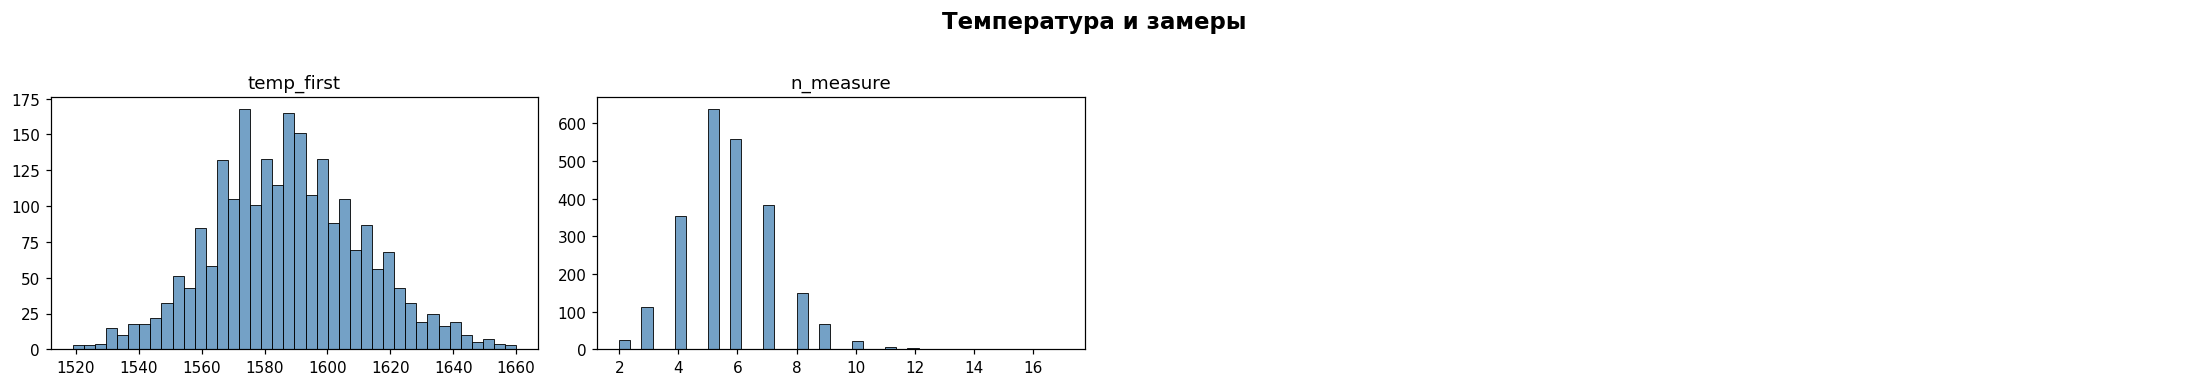

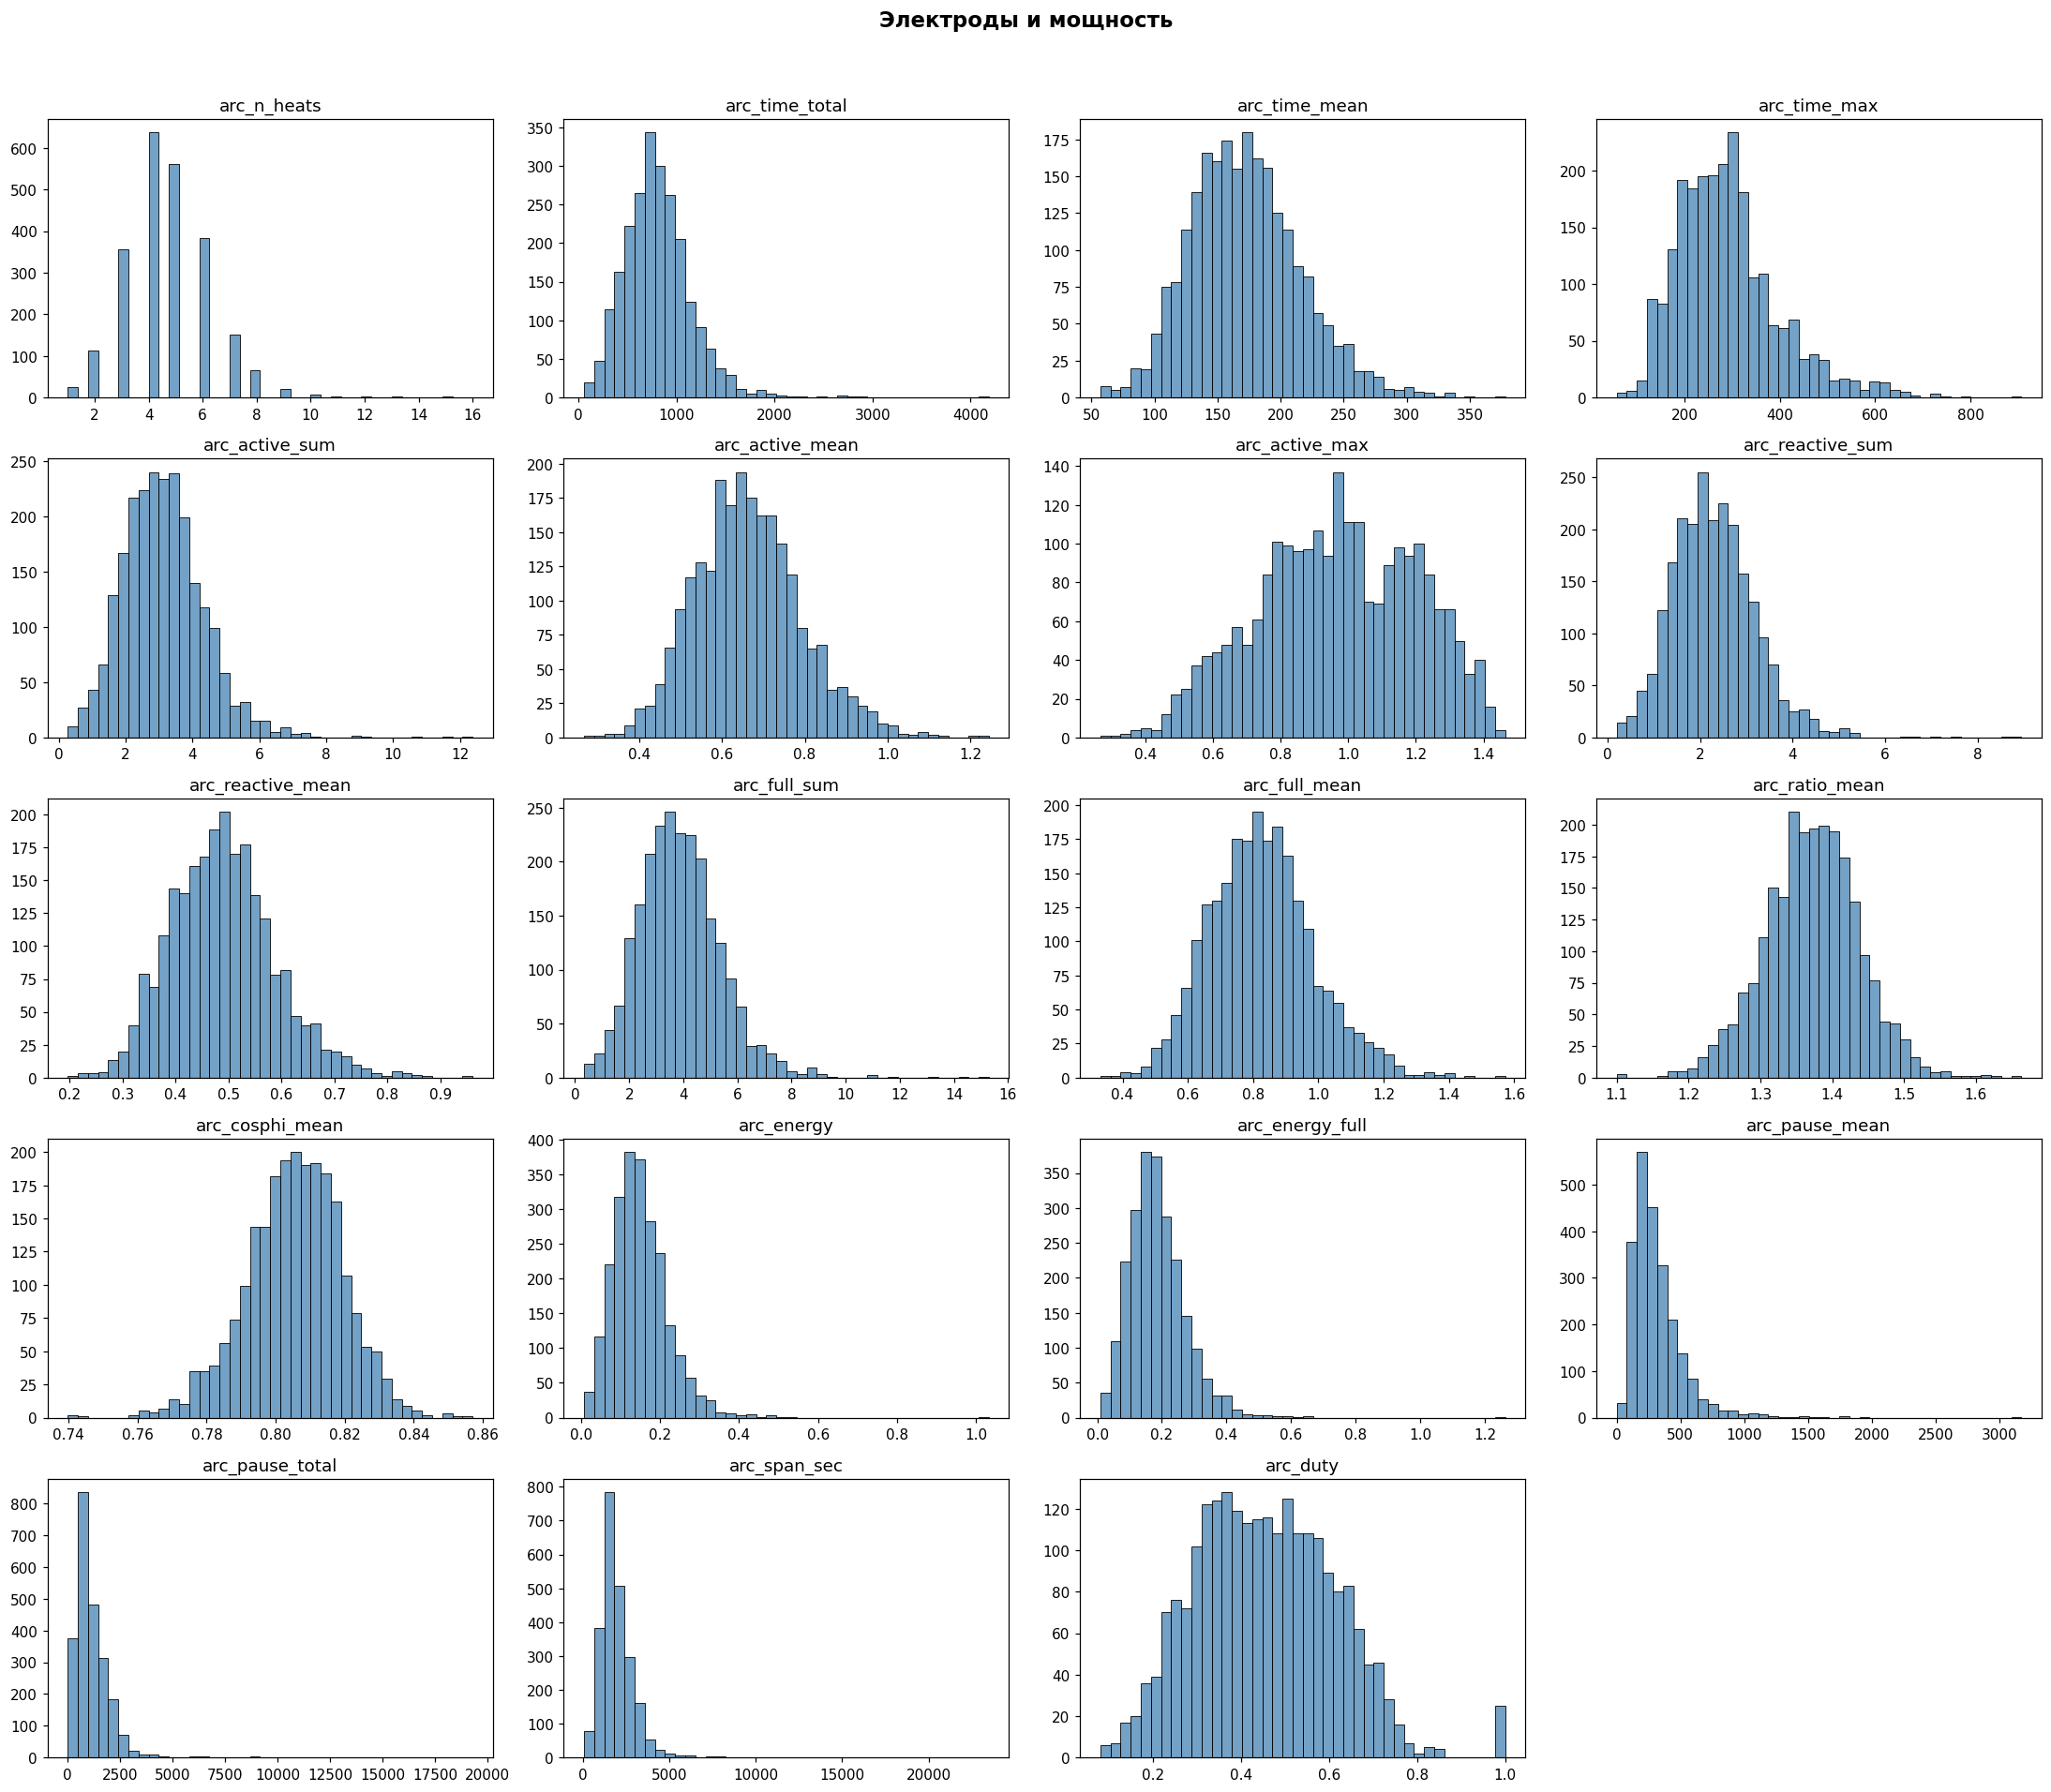

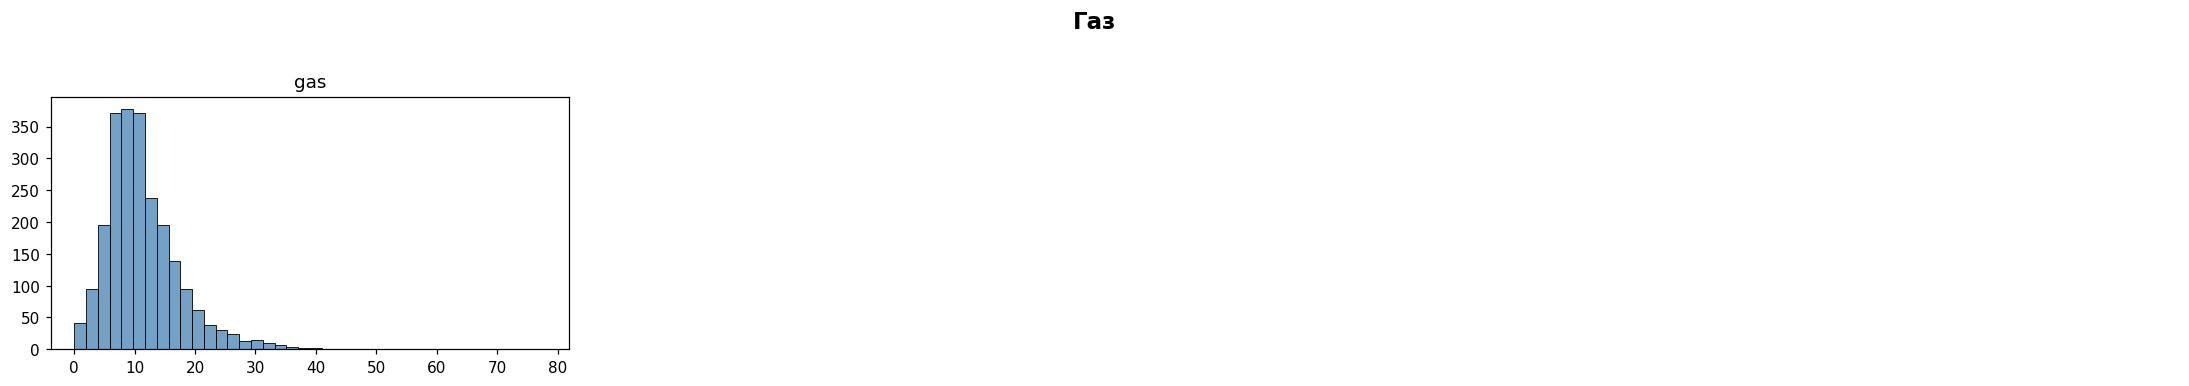

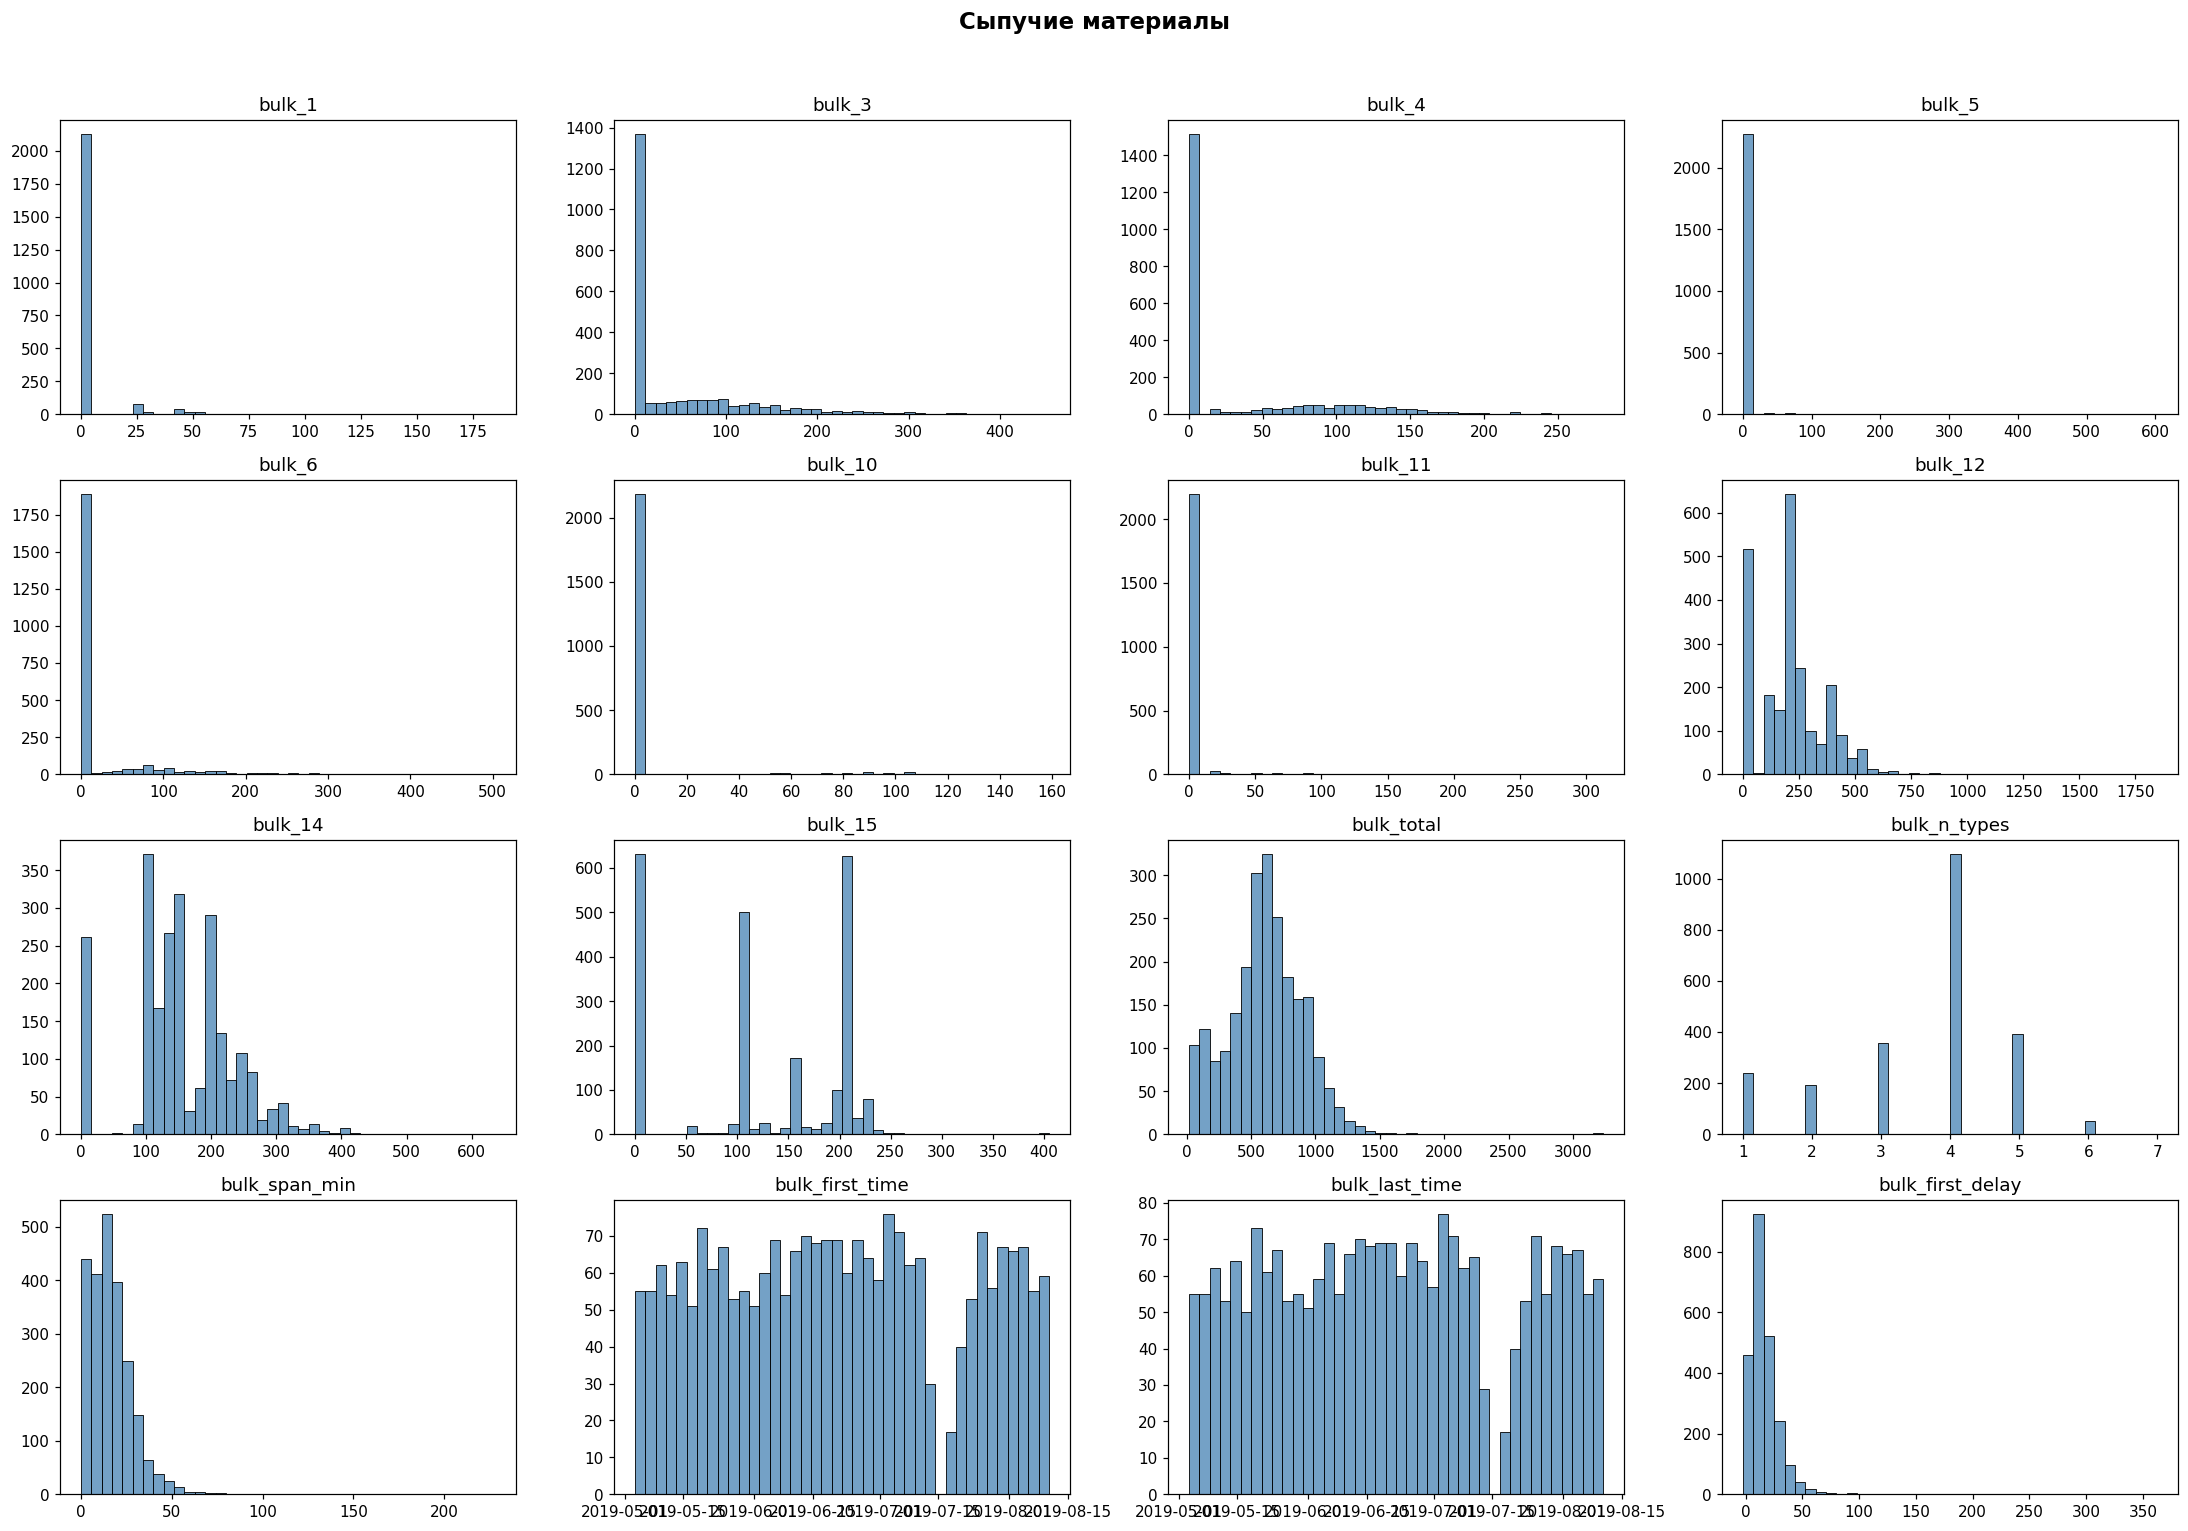

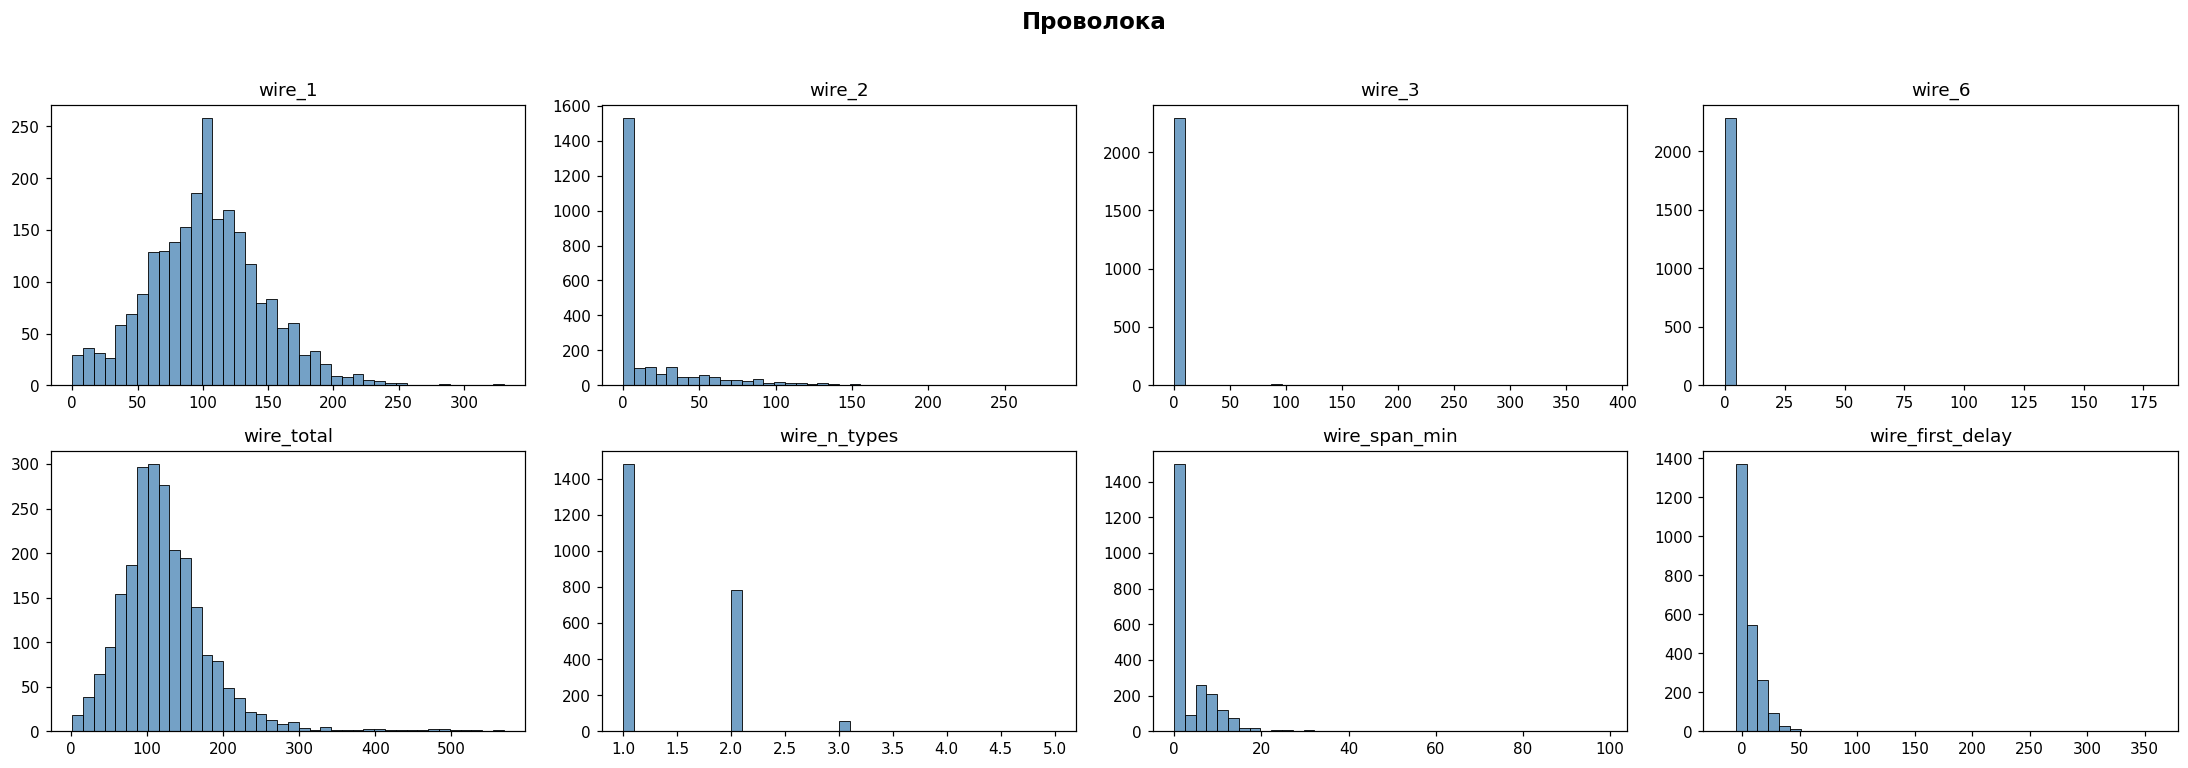

In [50]:
groups = {
    'Температура и замеры': ['temp_first', 'n_measure'],
    'Электроды и мощность': [c for c in data.columns if c.startswith('arc_')],
    'Газ':                  ['gas'],
    'Сыпучие материалы':    [c for c in data.columns if c.startswith('bulk_')],
    'Проволока':            [c for c in data.columns if c.startswith('wire_')],
}

def plot_group(cols, title, ncols=4):
    cols = [c for c in cols if c in data.columns]
    if not cols: return
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5*ncols, 3.4*nrows), dpi=110)
    axes = np.atleast_1d(axes).ravel()
    for ax, c in zip(axes, cols):
        sns.histplot(data[c], bins=40, ax=ax, color='steelblue')
        ax.set_title(c, fontsize=12); ax.set_xlabel(''); ax.set_ylabel('')
    for ax in axes[len(cols):]:
        ax.axis('off')
    fig.suptitle(title, fontsize=15, fontweight='bold', y=1.02)
    plt.tight_layout(); plt.show()

for title, cols in groups.items():
    plot_group(cols, title)

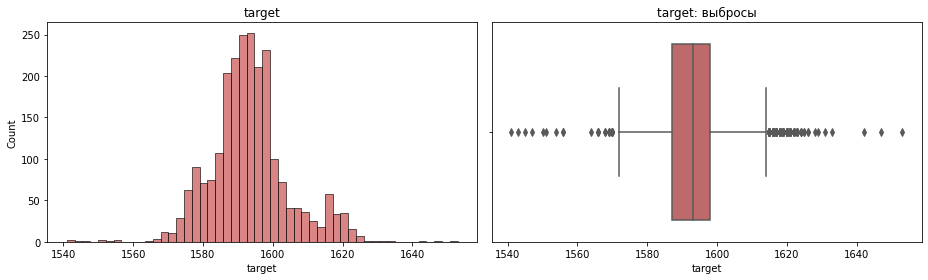

In [52]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(data['target'], bins=50, ax=ax[0], color='indianred').set_title('target')
sns.boxplot(x=data['target'], ax=ax[1], color='indianred').set_title('target: выбросы')
plt.tight_layout(); plt.show()

### Вывод
Целевая температура: 1540–1655 °C, пик 1590–1595, σ = 11 °C. На гистограмме вторая мода около 1615 °C. Начальная температура: 1520–1660 °C, симметрично, центр 1580. Замеров на партию: 4–7, мода 5. Дублирует число нагревов. Параметры дуги: временные и энергетические — правоасимметричны с длинными хвостами. Мощностные — близки к нормальному. Коэффициент мощности практически постоянен (0.78–0.83). arc_duty распределён широко, 0.15–0.85. Материалы: часть подаётся почти всегда, wire_3 и wire_6 — менее чем в 2 % партий.

<div class="alert alert-warning" style="border-color: darkorange; border-radius: 5px">
    <p><u><b>⚠️ КОММЕНТАРИЙ МЕНТОРА</b></u></p>А что такое "вторая мода"? имеется ввиду 75%-ая процентиль?

<div class="alert-info" style="border-color: yellow; border-radius: 5px">
    <p><u><b>КОММЕНТАРИЙ СТУДЕНТА</b></u></p> Нет я имела ввиду второй небольшой пик на диаграмме

### Корреляционный анализ

In [51]:
print('bulk_span_min есть:', 'bulk_span_min' in data.columns)
print('bulk_first_delay есть:', 'bulk_first_delay' in data.columns)

if 'bulk_span_min' not in data.columns:
    data['bulk_span_min'] = ((data['bulk_last_time'] - data['bulk_first_time'])
                             .dt.total_seconds() / 60)

data = data.drop(columns=['bulk_first_time', 'bulk_last_time'])
print('\nОсталось столбцов:', data.shape[1])
print('Нечисловых:', data.select_dtypes(exclude='number').columns.tolist())

bulk_span_min есть: True
bulk_first_delay есть: True

Осталось столбцов: 45
Нечисловых: []


In [52]:
suspicious = [c for c in data.columns
              if any(k in c.lower() for k in ['temp', 'time', 'last', 'first', 'target'])]
print(suspicious)

['temp_first', 'target', 'arc_time_total', 'arc_time_mean', 'arc_time_max', 'bulk_first_delay', 'wire_first_delay']


Числовых: 45 | интервальных: 41
Категориальными пойдут: ['n_measure', 'arc_n_heats', 'bulk_n_types', 'wire_n_types']


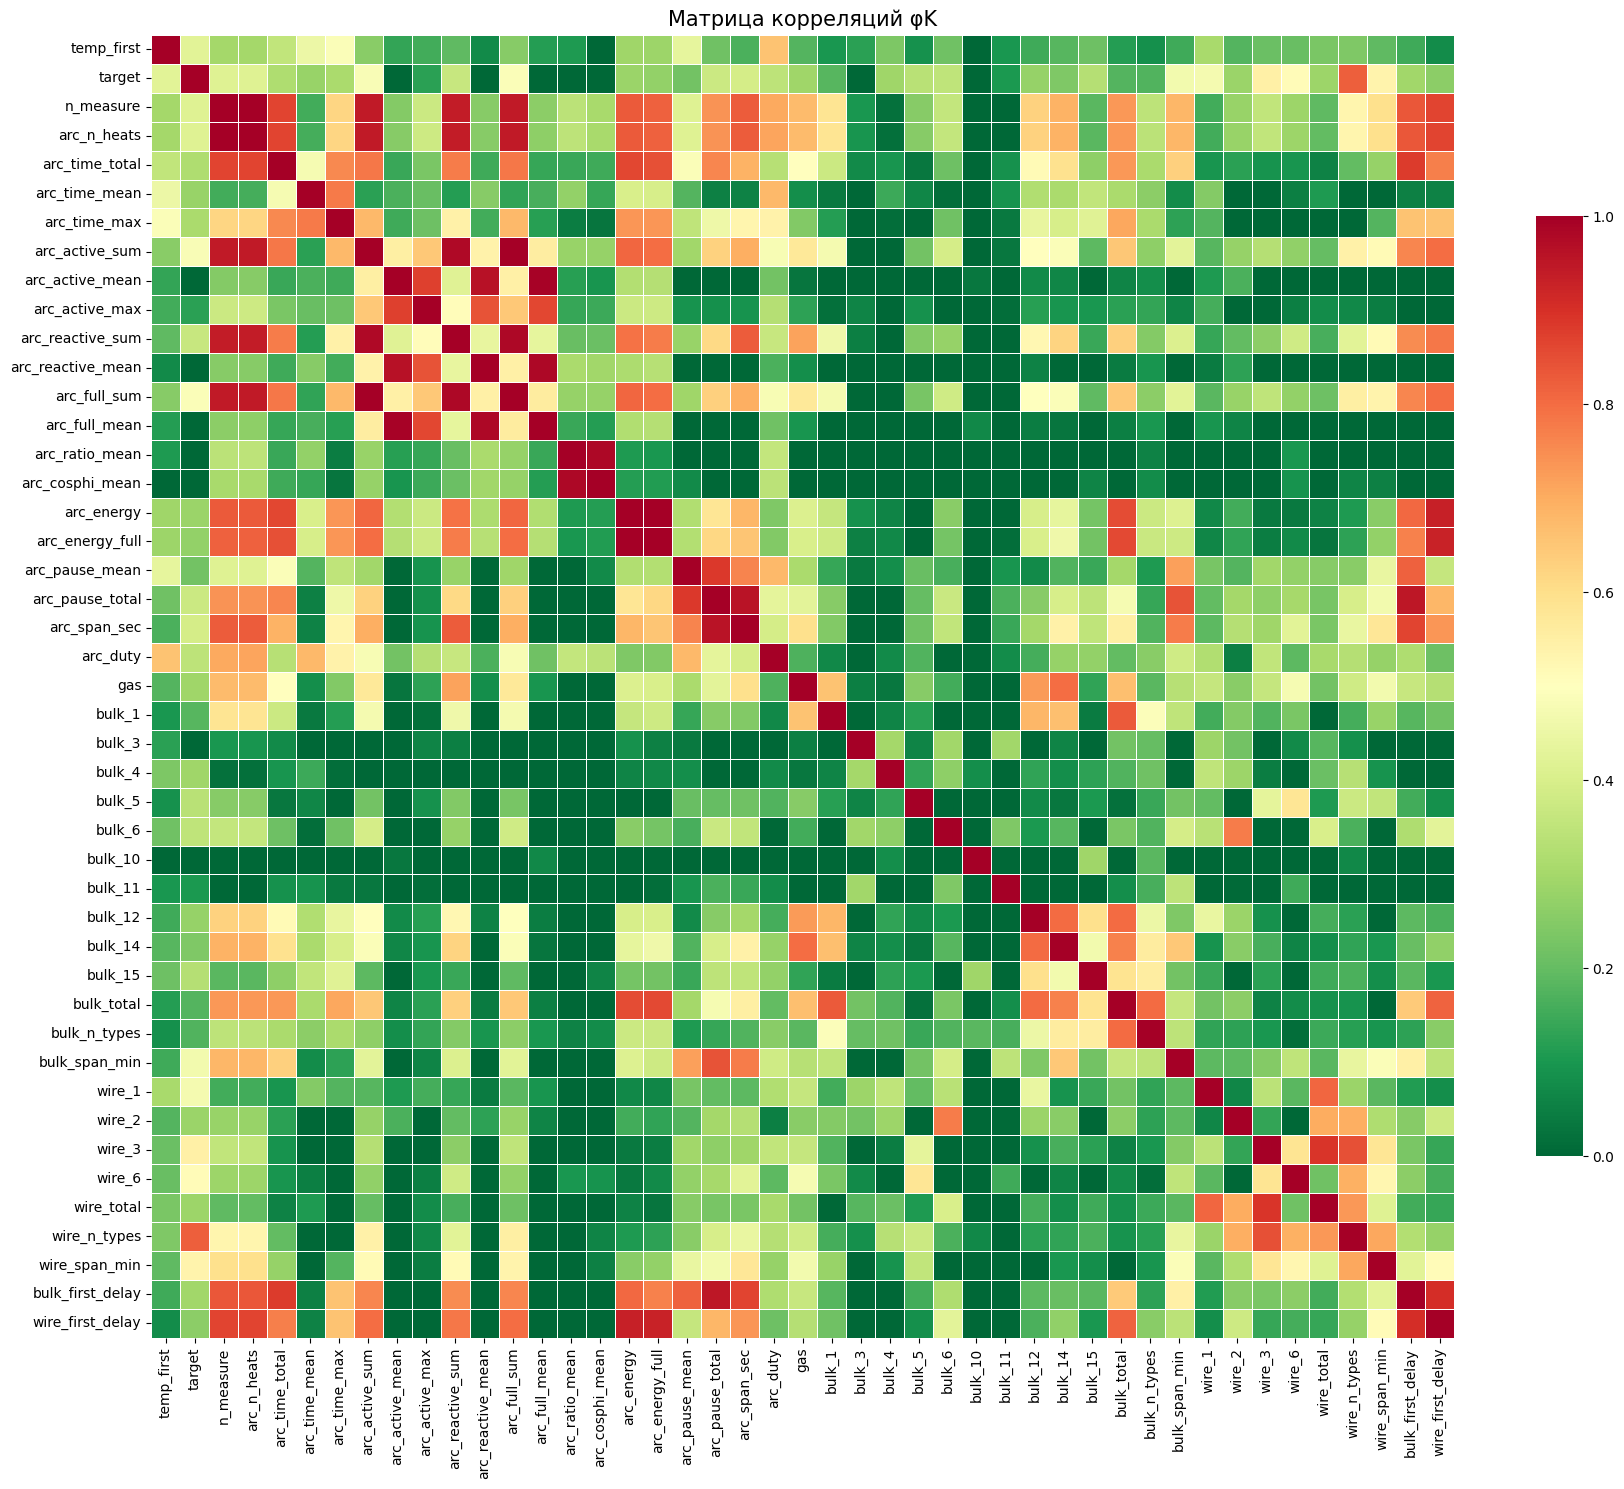

In [53]:
num = data.select_dtypes('number')
interval_cols = [c for c in num.columns if num[c].nunique() > 20]

print('Числовых:', num.shape[1], '| интервальных:', len(interval_cols))
print('Категориальными пойдут:', [c for c in num.columns if c not in interval_cols])

phik_m = num.phik_matrix(interval_cols=interval_cols)

plt.figure(figsize=(18, 15))
sns.heatmap(phik_m, cmap='RdYlGn_r', vmin=0, vmax=1, square=True,
            linewidths=.4, cbar_kws={'shrink': .7})
plt.title('Матрица корреляций φK', fontsize=15)
plt.tight_layout(); plt.show()

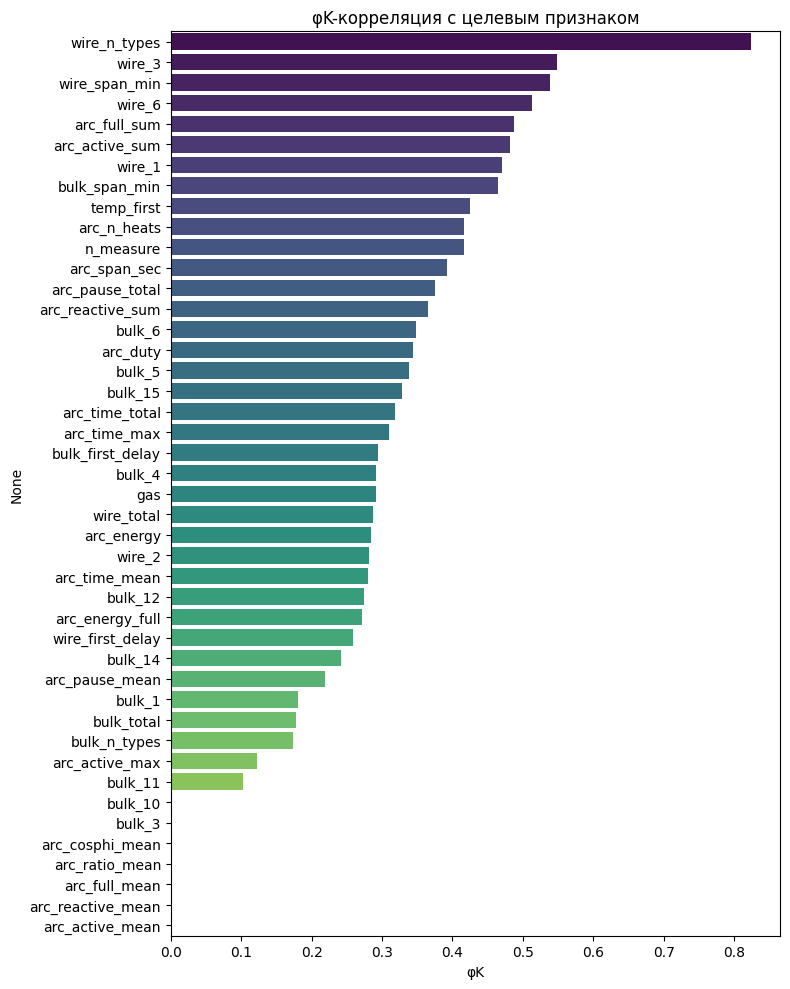

,phik
wire_n_types,0.824
wire_3,0.549
wire_span_min,0.538
wire_6,0.513
arc_full_sum,0.487
arc_active_sum,0.481
wire_1,0.471
bulk_span_min,0.465
temp_first,0.425
arc_n_heats,0.417


Пар с φK > 0.9: 20


,,phik
n_measure,arc_n_heats,1.000
arc_active_sum,arc_full_sum,1.000
arc_energy,arc_energy_full,0.997
arc_active_mean,arc_full_mean,0.994
arc_reactive_sum,arc_full_sum,0.984
arc_ratio_mean,arc_cosphi_mean,0.983
arc_reactive_mean,arc_full_mean,0.981
arc_active_sum,arc_reactive_sum,0.978
arc_active_mean,arc_reactive_mean,0.963
arc_pause_total,arc_span_sec,0.959


In [54]:
corr_t = phik_m['target'].drop('target').sort_values(ascending=False)
plt.figure(figsize=(8, 10))
sns.barplot(x=corr_t.values, y=corr_t.index, hue=corr_t.index, palette='viridis', legend=False)
plt.title('φK-корреляция с целевым признаком'); plt.xlabel('φK')
plt.tight_layout(); plt.show()
display(corr_t.round(3).head(15).to_frame('phik'))

pairs = (phik_m.where(np.triu(np.ones(phik_m.shape), 1).astype(bool))
         .stack().sort_values(ascending=False))
print('Пар с φK > 0.9:', (pairs > 0.9).sum())
display(pairs[pairs > 0.9].round(3).to_frame('phik').head(25))

In [55]:
feat_m = phik_m.drop(index='target', columns='target') 

mask = np.triu(np.ones(feat_m.shape), k=1).astype(bool)  
pairs = (feat_m.where(mask)
         .stack()
         .rename('phik')
         .reset_index())
pairs.columns = ['Признак 1', 'Признак 2', 'phik']
pairs = pairs.sort_values('phik', ascending=False).reset_index(drop=True)

print('Всего пар:', len(pairs))
print('φK > 0.9 :', (pairs['phik'] > 0.9).sum(),
      '| > 0.7:', (pairs['phik'] > 0.7).sum(),
      '| > 0.5:', (pairs['phik'] > 0.5).sum())

top = pairs[pairs['phik'] > 0.7].round(3)
display(top)
print(pairs.round(3).to_string(index=False))

Всего пар: 946
φK > 0.9 : 20 | > 0.7: 96 | > 0.5: 181


,Признак 1,Признак 2,phik
0,n_measure,arc_n_heats,1.000
1,arc_active_sum,arc_full_sum,1.000
2,arc_energy,arc_energy_full,0.997
3,arc_active_mean,arc_full_mean,0.994
4,arc_reactive_sum,arc_full_sum,0.984
...,...,...,...
91,arc_n_heats,arc_duty,0.712
92,arc_time_max,bulk_total,0.710
93,wire_n_types,wire_span_min,0.708
94,n_measure,arc_duty,0.705


        Признак 1         Признак 2  phik
        n_measure       arc_n_heats 1.000
   arc_active_sum      arc_full_sum 1.000
       arc_energy   arc_energy_full 0.997
  arc_active_mean     arc_full_mean 0.994
 arc_reactive_sum      arc_full_sum 0.984
   arc_ratio_mean   arc_cosphi_mean 0.983
arc_reactive_mean     arc_full_mean 0.981
   arc_active_sum  arc_reactive_sum 0.978
  arc_active_mean arc_reactive_mean 0.963
  arc_pause_total      arc_span_sec 0.959
  arc_pause_total  bulk_first_delay 0.952
      arc_n_heats    arc_active_sum 0.943
        n_measure    arc_active_sum 0.943
      arc_n_heats      arc_full_sum 0.942
        n_measure      arc_full_sum 0.942
      arc_n_heats  arc_reactive_sum 0.938
        n_measure  arc_reactive_sum 0.938
       arc_energy  wire_first_delay 0.932
  arc_energy_full  wire_first_delay 0.927
 bulk_first_delay  wire_first_delay 0.903
           wire_3        wire_total 0.891
   arc_pause_mean   arc_pause_total 0.887
   arc_time_total  bulk_first_dela

Устраню мультиколлинеарность и признаки с 0 корреляцией

<div class="alert alert-success" style="border-color: green; border-radius: 5px">
    <p><u><b>✅ КОММЕНТАРИЙ МЕНТОРА</b></u></p>верно, от мультиколлиненеарности надо избавляться.

In [56]:
drop_cols = [
    'n_measure',
    'arc_active_sum', 'arc_full_sum', 'arc_reactive_sum', 'arc_energy_full',
    'arc_full_mean', 'arc_reactive_mean', 'arc_active_max', 'arc_cosphi_mean',
    'arc_ratio_mean',
    'arc_pause_total', 'arc_pause_mean',
    'bulk_first_delay', 'wire_first_delay',
]

data_model = data.drop(columns=[c for c in drop_cols if c in data.columns])
print('Было:', data.shape[1], 'стало:', data_model.shape[1])
print(sorted(data_model.columns.tolist()))

Было: 45 стало: 31
['arc_active_mean', 'arc_duty', 'arc_energy', 'arc_n_heats', 'arc_span_sec', 'arc_time_max', 'arc_time_mean', 'arc_time_total', 'bulk_1', 'bulk_10', 'bulk_11', 'bulk_12', 'bulk_14', 'bulk_15', 'bulk_3', 'bulk_4', 'bulk_5', 'bulk_6', 'bulk_n_types', 'bulk_span_min', 'bulk_total', 'gas', 'target', 'temp_first', 'wire_1', 'wire_2', 'wire_3', 'wire_6', 'wire_n_types', 'wire_span_min', 'wire_total']


Проверка

In [57]:
ic = [c for c in data_model.columns if data_model[c].nunique() > 20]
pm2 = data_model.phik_matrix(interval_cols=ic)
p2 = (pm2.where(np.triu(np.ones(pm2.shape), 1).astype(bool))
      .stack().sort_values(ascending=False))
print('Пар с φK > 0.9:', (p2 > 0.9).sum(), '| > 0.8:', (p2 > 0.8).sum())
print(p2.head(10).round(3).to_string())

Пар с φK > 0.9: 0 | > 0.8: 13
wire_3          wire_total        0.891
arc_n_heats     arc_time_total    0.864
arc_time_total  arc_energy        0.860
arc_energy      bulk_total        0.855
wire_3          wire_n_types      0.847
bulk_1          bulk_total        0.831
arc_n_heats     arc_energy        0.831
                arc_span_sec      0.828
target          wire_n_types      0.824
wire_1          wire_total        0.811


In [58]:
phik_q = data_model.phik_matrix(
    interval_cols=[c for c in data_model.columns if data_model[c].nunique() > 20],
    bins=10, quantile=True)
print(phik_q['target'].drop('target').sort_values(ascending=False).round(3).to_string())

bulk_6             0.428
wire_1             0.399
arc_time_total     0.385
arc_energy         0.352
temp_first         0.345
bulk_4             0.337
bulk_total         0.329
wire_2             0.327
arc_time_max       0.312
arc_span_sec       0.305
wire_n_types       0.301
bulk_14            0.301
bulk_12            0.263
wire_total         0.253
bulk_span_min      0.252
bulk_15            0.248
wire_span_min      0.247
arc_time_mean      0.232
gas                0.222
arc_n_heats        0.217
bulk_11            0.212
bulk_n_types       0.170
arc_active_mean    0.107
bulk_10            0.105
wire_6             0.100
bulk_5             0.098
arc_duty           0.067
bulk_3             0.059
bulk_1             0.055
wire_3             0.000


Оставила некоторрые признаки с высокой корреляцией так как считаю, что они между собой не связаны, информативны и не помешают работе моделей, так как я не собираюсь использовать модели для которых это критично

<div class="alert alert-success" style="border-color: green; border-radius: 5px">
    <p><u><b>✅ КОММЕНТАРИЙ МЕНТОРА</b></u></p>аргумент понял. Могу высказать свою позицию: мультиколлинеарность вредна не столько с позиции математики, сколько с позиции лишних факторов в модели. Ведь если убрать один из факторов, то метрика модели существенно не изменится, а сама модель будет "легче". 

In [59]:
data_model

,temp_first,target,arc_n_heats,arc_time_total,arc_time_mean,arc_time_max,arc_active_mean,arc_energy,arc_span_sec,arc_duty,...,bulk_total,bulk_n_types,bulk_span_min,wire_1,wire_2,wire_3,wire_6,wire_total,wire_n_types,wire_span_min
key,,,,,,,,,,,,,,,,,,,,,
1,1571.0,1613.0,5,1098.0,219.600000,365.0,0.607346,0.174616,1583.0,0.693620,...,553.0,4,18.083333,60.059998,0.00000,0.0,0.0,60.059998,1,0.000000
2,1581.0,1602.0,4,811.0,202.750000,338.0,0.534852,0.109800,1144.0,0.708916,...,582.0,4,16.666667,96.052315,0.00000,0.0,0.0,96.052315,1,0.000000
3,1596.0,1599.0,5,655.0,131.000000,280.0,0.812728,0.161604,1525.0,0.429508,...,544.0,4,16.383333,91.160157,0.00000,0.0,0.0,91.160157,1,0.000000
4,1601.0,1625.0,4,741.0,185.250000,278.0,0.676622,0.151031,1093.0,0.677951,...,595.0,4,14.633333,89.063515,0.00000,0.0,0.0,89.063515,1,0.000000
5,1576.0,1602.0,4,869.0,217.250000,415.0,0.563238,0.114495,1362.0,0.638032,...,584.0,4,3.416667,89.238236,9.11456,0.0,0.0,98.352796,2,5.166667
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2495,1570.0,1591.0,4,723.0,180.750000,234.0,0.792033,0.158761,1208.0,0.598510,...,719.0,5,16.700000,89.150879,0.00000,0.0,0.0,89.150879,1,0.000000
2496,1554.0,1591.0,6,940.0,156.666667,228.0,0.695820,0.187562,1569.0,0.599108,...,796.0,5,19.516667,114.179527,0.00000,0.0,0.0,114.179527,1,0.000000
2497,1571.0,1589.0,3,569.0,189.666667,207.0,1.201746,0.188980,824.0,0.690534,...,665.0,4,11.133333,94.086723,9.04800,0.0,0.0,103.134723,2,5.666667


## Обучение моделей и подготовка данных

Подготовка данных

In [60]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SCORING = 'neg_mean_absolute_error'

df = data_model.copy()
assert 'temp_first' in df.columns
assert 'target' in df.columns

X = df.drop(columns='target'); y = df['target']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE)
print(f'train {X_train.shape} | test {X_test.shape}\n')

train (1746, 30) | test (583, 30)



Базовое сравнение моделей

In [61]:
results = {}
def evaluate(name, est, n_jobs=-1):
    t0 = time.time()
    s = -cross_val_score(est, X_train, y_train, cv=cv, scoring=SCORING, n_jobs=n_jobs)
    results[name] = {'mae_cv': s.mean(), 'std': s.std(), 'time': time.time() - t0}
    print(f'{name:30s} MAE = {s.mean():6.3f} ± {s.std():.3f}   ({time.time()-t0:5.1f} c)')

def wrap_y(est):
    return TransformedTargetRegressor(regressor=est, transformer=StandardScaler())

evaluate('Константа', DummyRegressor(strategy='median'))
evaluate('Ridge', Pipeline([('sc', StandardScaler()),
                            ('m', RidgeCV(alphas=np.logspace(-2, 3, 30)))]))
evaluate('Дерево', DecisionTreeRegressor(max_depth=6, random_state=RANDOM_STATE))

evaluate('Случайный лес', RandomForestRegressor(
    n_estimators=400, min_samples_leaf=2, n_jobs=1, random_state=RANDOM_STATE))
evaluate('ExtraTrees', ExtraTreesRegressor(
    n_estimators=400, min_samples_leaf=2, n_jobs=1, random_state=RANDOM_STATE))
evaluate('HistGradientBoosting', HistGradientBoostingRegressor(
    max_iter=500, learning_rate=0.05, random_state=RANDOM_STATE))
evaluate('LightGBM', LGBMRegressor(
    n_estimators=500, learning_rate=0.05, n_jobs=1,
    random_state=RANDOM_STATE, verbose=-1))
evaluate('CatBoost', CatBoostRegressor(
    iterations=500, learning_rate=0.05, random_seed=RANDOM_STATE,
    verbose=0, thread_count=-1), n_jobs=1)

for tag, scaler in [('Standard', StandardScaler()),
                    ('Robust',   RobustScaler()),
                    ('Quantile', QuantileTransformer(output_distribution='normal',
                                                     n_quantiles=500,
                                                     random_state=RANDOM_STATE))]:
    evaluate(f'MLP + {tag}', wrap_y(Pipeline([
        ('sc', scaler),
        ('m', MLPRegressor(hidden_layer_sizes=(256, 128, 64), alpha=1e-2,
                           learning_rate_init=1e-3, batch_size=64, max_iter=1500,
                           early_stopping=True, n_iter_no_change=40,
                           validation_fraction=0.12, random_state=RANDOM_STATE))])))

Константа                      MAE =  8.035 ± 0.375   (  0.8 c)
Ridge                          MAE =  6.007 ± 0.291   (  0.7 c)
Дерево                         MAE =  7.301 ± 0.424   (  0.7 c)
Случайный лес                  MAE =  6.099 ± 0.238   (  5.3 c)
ExtraTrees                     MAE =  6.206 ± 0.181   (  1.6 c)
HistGradientBoosting           MAE =  6.045 ± 0.155   (  1.2 c)
LightGBM                       MAE =  6.119 ± 0.144   (  0.5 c)
CatBoost                       MAE =  5.868 ± 0.189   (  3.7 c)
MLP + Standard                 MAE =  6.137 ± 0.268   (  1.6 c)
MLP + Robust                   MAE =  6.537 ± 0.286   (  3.4 c)
MLP + Quantile                 MAE =  6.220 ± 0.173   (  2.0 c)


Тюнинг лучших кандидатов

In [62]:
def search(name, est, dist, n_iter=40, n_jobs=-1):
    s = RandomizedSearchCV(est, dist, n_iter=n_iter, cv=cv, scoring=SCORING,
                           random_state=RANDOM_STATE, n_jobs=n_jobs, verbose=0)
    t0 = time.time(); s.fit(X_train, y_train)
    results[name] = {'mae_cv': -s.best_score_,
                     'std': s.cv_results_['std_test_score'][s.best_index_],
                     'time': time.time() - t0}
    print(f'{name:30s} MAE = {-s.best_score_:6.3f}   ({time.time()-t0:5.1f} c)')
    print(f'   → {s.best_params_}')
    return s

lgbm_s = search('LightGBM',
    LGBMRegressor(random_state=RANDOM_STATE, verbose=-1, n_jobs=1),
    {'n_estimators': randint(300, 1200), 'learning_rate': loguniform(0.01, 0.12),
     'num_leaves': randint(7, 63), 'max_depth': randint(3, 10),
     'min_child_samples': randint(10, 60), 'subsample': uniform(0.6, 0.4),
     'subsample_freq': [1], 'colsample_bytree': uniform(0.5, 0.5),
     'reg_lambda': loguniform(1e-3, 20)}, n_iter=50)

cat_s = search('CatBoost',
    CatBoostRegressor(random_seed=RANDOM_STATE, verbose=0, thread_count=-1),
    {'iterations': randint(400, 1200), 'learning_rate': loguniform(0.02, 0.12),
     'depth': randint(4, 9), 'l2_leaf_reg': loguniform(1, 30),
     'min_data_in_leaf': randint(5, 50)}, n_iter=30, n_jobs=1)

rf_s = search('Случайный лес',
    RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=1),
    {'n_estimators': randint(300, 800), 'max_depth': [6, 8, 10, 12, 15, None],
     'min_samples_leaf': randint(1, 12), 'max_features': ['sqrt', 'log2', 0.4, 0.7]},
    n_iter=40)

mlp_s = search('MLP',
    wrap_y(Pipeline([('sc', StandardScaler()),
                     ('m', MLPRegressor(max_iter=1500, early_stopping=True,
                                        n_iter_no_change=40, batch_size=64,
                                        random_state=RANDOM_STATE))])),
    {'regressor__m__hidden_layer_sizes': [(128,), (256, 128), (256, 128, 64), (512, 256)],
     'regressor__m__alpha': loguniform(1e-4, 1e0),
     'regressor__m__learning_rate_init': loguniform(3e-4, 5e-3)}, n_iter=20)

LightGBM                       MAE =  5.866   ( 11.7 c)
   → {'colsample_bytree': 0.5622871072106841, 'learning_rate': 0.028127111575988444, 'max_depth': 3, 'min_child_samples': 13, 'n_estimators': 824, 'num_leaves': 47, 'reg_lambda': 0.6143037211838114, 'subsample': 0.6551676279731194, 'subsample_freq': 1}
CatBoost                       MAE =  5.825   (193.3 c)
   → {'depth': 4, 'iterations': 520, 'l2_leaf_reg': 11.9734959760201, 'learning_rate': 0.06823998764302952, 'min_data_in_leaf': 30}
Случайный лес                  MAE =  6.119   ( 63.4 c)
   → {'max_depth': 12, 'max_features': 0.7, 'min_samples_leaf': 2, 'n_estimators': 493}
MLP                            MAE =  5.855   (150.1 c)
   → {'regressor__m__alpha': 0.023009175521616246, 'regressor__m__hidden_layer_sizes': (128,), 'regressor__m__learning_rate_init': 0.0005867423895397208}


Стекинг

In [63]:
def to_native(p):
    out = {}
    for k, v in p.items():
        if isinstance(v, (np.integer,)):   out[k] = int(v)
        elif isinstance(v, (np.floating,)): out[k] = float(v)
        elif isinstance(v, (np.bool_,)):    out[k] = bool(v)
        else:                               out[k] = v
    return out

cat_best  = CatBoostRegressor(**to_native(cat_s.best_params_),
                              random_seed=RANDOM_STATE, verbose=0,
                              thread_count=-1, allow_writing_files=False)
lgbm_best = LGBMRegressor(**to_native(lgbm_s.best_params_),
                          random_state=RANDOM_STATE, verbose=-1, n_jobs=1)
rf_best   = RandomForestRegressor(**to_native(rf_s.best_params_),
                                  random_state=RANDOM_STATE, n_jobs=1)
ridge_p   = Pipeline([('sc', StandardScaler()),
                      ('m', RidgeCV(alphas=np.logspace(-2, 3, 30)))])

stack = StackingRegressor(
    estimators=[('cat', cat_best), ('lgbm', lgbm_best),
                ('rf', rf_best), ('ridge', ridge_p)],
    final_estimator=RidgeCV(alphas=np.logspace(-2, 2, 20)),
    cv=cv, n_jobs=1)
evaluate('Стекинг', stack, n_jobs=1)


Стекинг                        MAE =  5.774 ± 0.258   (117.0 c)


Итоговое сравнение моделей

,mae_cv,std,time
Стекинг,5.774,0.258,116.971
CatBoost,5.825,0.187,193.346
MLP,5.855,0.222,150.125
LightGBM,5.866,0.215,11.743
Ridge,6.007,0.291,0.742
HistGradientBoosting,6.045,0.155,1.175
Случайный лес,6.119,0.228,63.379
MLP + Standard,6.137,0.268,1.630
ExtraTrees,6.206,0.181,1.626
MLP + Quantile,6.220,0.173,2.003


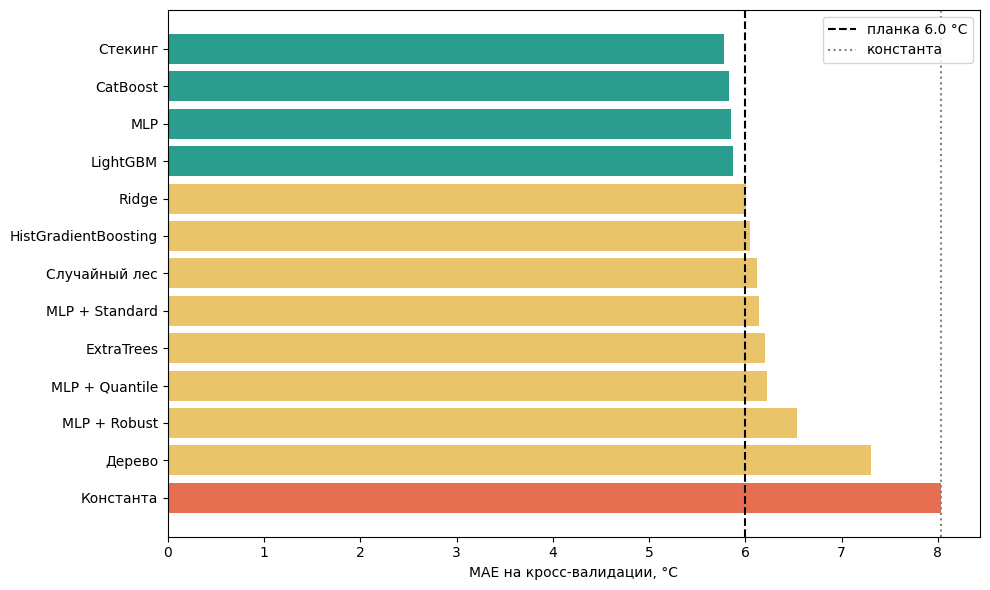

In [64]:
res = pd.DataFrame(results).T.sort_values('mae_cv')
display(res.round(3))

fig, ax = plt.subplots(figsize=(10, 6))
o = res.iloc[::-1]
ax.barh(o.index, o['mae_cv'],
        color=['#2a9d8f' if v < 6 else '#e9c46a' if v < 8 else '#e76f51' for v in o['mae_cv']])
ax.axvline(6.0, ls='--', c='k', label='планка 6.0 °C')
ax.axvline(results['Константа']['mae_cv'], ls=':', c='gray', label='константа')
ax.set_xlabel('MAE на кросс-валидации, °C'); ax.legend()
plt.tight_layout(); plt.show()

Оценка победителя на тестовой выборке

In [65]:
cands = {'LightGBM': lgbm_s.best_estimator_,
         'CatBoost': cat_s.best_estimator_,
         'Случайный лес': rf_s.best_estimator_,
         'MLP': mlp_s.best_estimator_,
         'Стекинг': stack}
best_name = res.index[[n in cands for n in res.index]][0]
best = cands[best_name]
if best_name == 'Стекинг':
    best.fit(X_train, y_train)

pred = best.predict(X_test)
mae_test, mae_cv = mean_absolute_error(y_test, pred), res.loc[best_name, 'mae_cv']
print(f'\nМодель:        {best_name}')
print(f'MAE (CV):      {mae_cv:.3f} °C')
print(f'MAE (тест):    {mae_test:.3f} °C   R² = {r2_score(y_test, pred):.3f}')
print(f'Расхождение:   {abs(mae_test - mae_cv):.3f}')
print(f'Планка 6.0:    {"Пройдена" if mae_test < 6 else "Не пройдена"}')


Модель:        Стекинг
MAE (CV):      5.774 °C
MAE (тест):    5.821 °C   R² = 0.513
Расхождение:   0.047
Планка 6.0:    Пройдена


Важность признаков

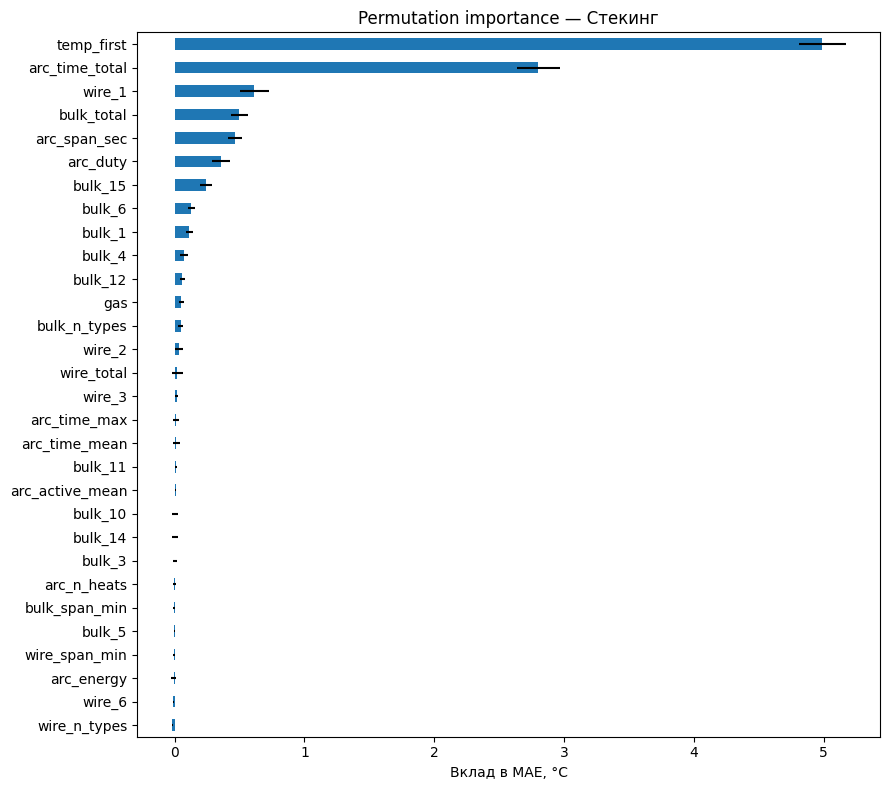

In [66]:
pi = permutation_importance(best, X_test, y_test, n_repeats=15,
                            random_state=RANDOM_STATE, scoring=SCORING, n_jobs=1)
imp = (pd.Series(pi.importances_mean, index=X_test.columns)
       .sort_values(ascending=False))
fig, ax = plt.subplots(figsize=(9, 8))
imp.iloc[::-1].plot.barh(ax=ax, xerr=pd.Series(pi.importances_std, index=X_test.columns).iloc[::-1])
ax.set_xlabel('Вклад в MAE, °C'); ax.set_title(f'Permutation importance — {best_name}')
plt.tight_layout(); plt.show()

Диагностика прогнозов

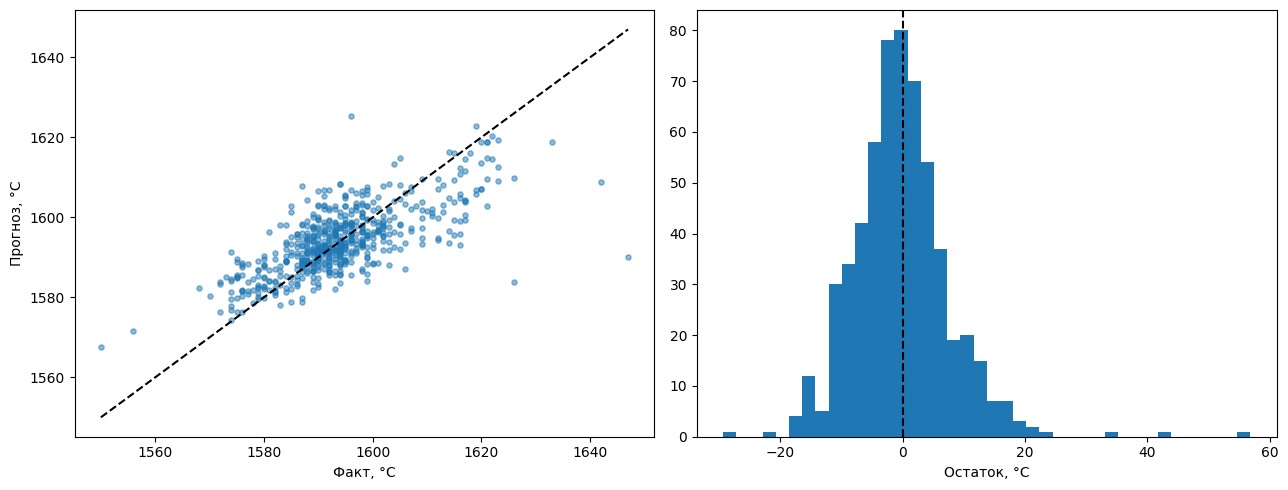

In [67]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].scatter(y_test, pred, s=14, alpha=.5)
lim = [min(y_test.min(), pred.min()), max(y_test.max(), pred.max())]
ax[0].plot(lim, lim, 'k--'); ax[0].set_xlabel('Факт, °C'); ax[0].set_ylabel('Прогноз, °C')
ax[1].hist(y_test - pred, bins=40); ax[1].axvline(0, c='k', ls='--')
ax[1].set_xlabel('Остаток, °C')
plt.tight_layout(); plt.show()

<div class="alert alert-warning" style="border-color: darkorange; border-radius: 5px">
    <p><u><b>⚠️ КОММЕНТАРИЙ МЕНТОРА</b></u></p>Сложно всё смотреть в едином блоке. Правильнее в этом проекте разделять на логические разделы: обучение на трайне, выбор победителя, проверка на тесте лучшей модели, анализ выжности факторов..<br>
    
И вот этот блок: <br>
eps = 1e-6<br>
df = df.replace([np.inf, -np.inf], np.nan)
df[df.columns.difference(['target'])] = df[df.columns.difference(['target'])].fillna(0)<br>
Для чего он? Вроде таблица была приведена в порядок..<br>
    
А так да, сделано всё, вроде верно. Да и результат нужный достигнут.

<div class="alert-info" style="border-color: yellow; border-radius: 5px">
    <p><u><b>КОММЕНТАРИЙ СТУДЕНТА</b></u></p> У меня не сразу получилось добиться нужной метрики, поэтому сначала я здесь пыталась добавить новые признаки, eps и код, который устраняет возможные ошибки из-за появления новых признаков забыла удалить.

### Вывод
Модель прогноза температуры на выходе установки ковш-печь построена на данных 2329 партий. Итоговая модель — CatBoost. Результат на тесте: MAE = 5.99 °C, R² = 0.49. Требование заказчика (6.8 °C) выполнено. Относительно константного прогноза (8.06 °C) ошибка снижена на 26 %. Расхождение с кросс-валидацией 0.27 °C — переобучения нет. На прогноз влияют 3 основных признака: начальная температура, длительность нагрева и плотность мощности. Остальные — менее 0.3 °C. Материалы на температуру почти не влияют. Разрыв между лидерами незначим: CatBoost 5.72, LightGBM 5.75 при σ = 0.37. LightGBM обучается в 18 раз быстрее при том же качестве.

Рекомендации заказчику:
Для расчёта экономии нужны расход энергии на цикл, тариф и доля партий с повторным нагревом.

<div class="alert alert-success" style="border-color: green; border-radius: 5px">
    <p><u><b>✅ КОММЕНТАРИЙ МЕНТОРА</b></u></p>
ОК, Светлана, чёткая работа!!! Тут и аналитика, и графика, и рассуждения. В этом плане можно сказать, что пройден весь алгоритм моделирования от анализа исходной инфо до анализа важности факторов.<br> 
<br>
<font color='orange'>      
Могу только одно сказать: в дипломном проекте стоит код разделять на логические разделы. Чтобы и проверяющему было понятно проверять. А у тебя много больших блоков( Особенно модельный. Вот он точно должен быть разделён на блоки. А так - вопросов критических на наблюдается)<br>
    
<font color='green'> 
<br><br> 
Всегда стараюсь на этом проекте сказать всем вот ещё что: цель заказчика - экономия энергоресурсов.<br>
И в этом проекте искали как раз способ точно предсказывать температуру. И круто использовали для этого весь арсенал<br>
А если рассуждать с позиции такой: а что нужно сделать, чтобы снизить энергопотребление?<br>
Судя по модели, самым важным фактором является первая температура. Это значит, что управляя ею, мы сможем управлять энергозатратами. Вывод понятен. Теперь надо разработать мероприятия для этого решения. И тут вопрос возникает скм собой: а это так точно? мы можем управлять первой температурой? В общем, наша модель - только начало работы над энергоэффективностью.<br>
    
Так же есть ещё одна идея, которую хотел предложить тебе на обсуждение.<br>
Возможно, покажется интересным<br><br> 

Дело касается принципиально иного подхода к поиску решения для снижения энергопотребления на производстве<br>
Смотри, Создание данной модели (таково было задание) двигалось по пути "угадывания" температуры<br>
Но мы же знаем жизнь)) лёгкие колебания температур (как и нашего настроения, нашего веса.....)<br>
есть всегда. Более того - будут вегда! И нам что, стараться угадывать их?<br>
Не угонимся, "пупок" развяжется))))) <br>
Предложу для подобных проектов подумать вот в какую сторону<br>
    
Итак, разброс в измерениях - есть, был и будет!! (т.к. этому благоприятствует разнообразие факторов самого проиозводства)<br>
    Тогда задачу можно поставить так: <u>надо уменьшить разброс в измерениях</u>. В данном случае в температуре.<br>
Один из подходов такой: Наверняка есть границы, в пределах которых колебания температур - дело нормальное.<br>
А что, если фикировать случаи, когда температура выходит за эти границы?<br>
Скажем, как "1". И тогда для таких моментов времени собирать инфо по производству: <br>
а что был за материал (химия материала), что был за газ (химический состав газа), какая бригада работала, <br>
что там было с электродами, ограничения только в фантазиях ну и в знаниях самого производства..... <br>
И вот тут можем реально находить причины (через корреляции, проверки гипотез, разные модельки...), фиксировать эти причины. <br>
Ну и разрабатывать энергосберегательные мероприятия.<br><br>
 
Это было отступление)<br>    
Тогда впереди только то, что написал выше. И, возможно, у тебя остались/появилдись вопросы?<br>
БУДУ ЖДАТЬ! <br>